<a href="https://colab.research.google.com/github/kavy988/ai-ml-dl-learning/blob/main/machine-learning/ml2_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Ch2- short Notes

Model starts

TBR - only for refrence
* 1 district = 1 block group = 1 row = 1 instance
* 16,512 districts = 16,512 instances = 16,512 rows
* using plain batch learning method for this project.
* housing_median_age = how old the houses in that district are (median age in years), not how long they can last.

* df.iloc[rows, columns]
1. before comma -> which rows(by position)
2. after comma -> which columns (by position)
3. : alone -> means "all"

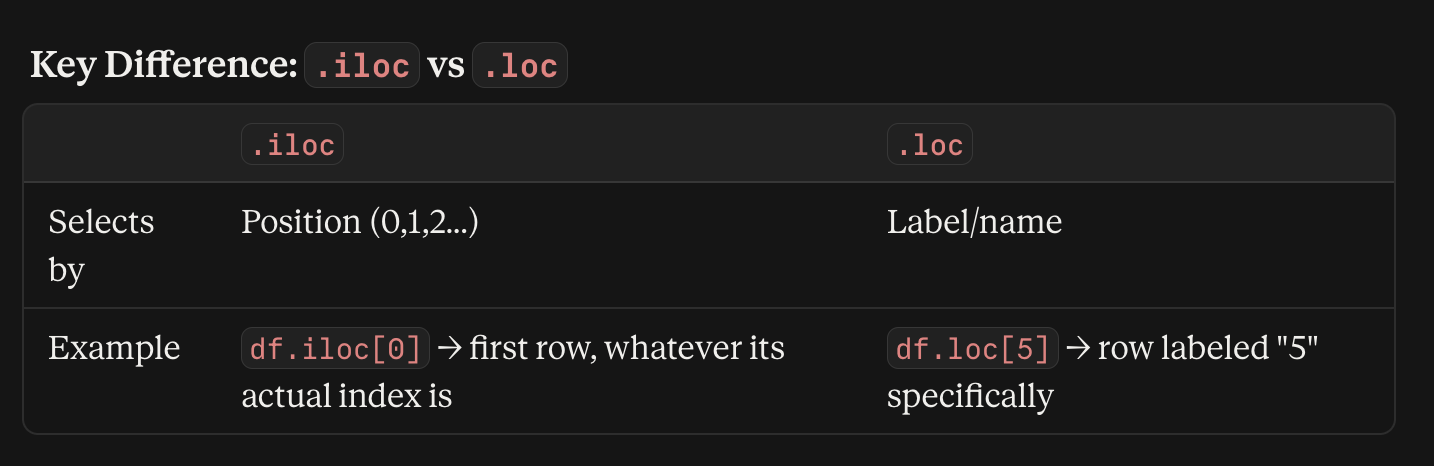

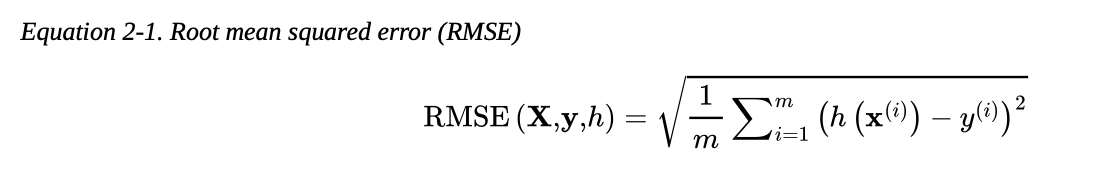

* X is a matrix
* m is the no. of instance so if districts = 2000 so , m = 2000.
* h (hypothesis) - system's prediction function

In [1]:
# setup
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import sklearn

from pathlib import Path
import tarfile # for handling .tar compressed files (extract /create )
import requests # for requests
import urllib.request # for fetching urls /files

In [2]:
# # get the data
# creating an function to fetch and load the data
def load_housing_data() :
  tarball_path = Path("datasets/housing.tgz")

  if not tarball_path.is_file():
    Path("datasets").mkdir(parents = True , exist_ok = True)
    url = "https://github.com/ageron/data/raw/main/housing.tgz"
    urllib.request.urlretrieve(url , tarball_path)

    with tarfile.open(tarball_path) as housing_tarball:
      housing_tarball.extractall(path = "datasets" , filter = "data")

  return pd.read_csv(Path("datasets/housing/housing.csv"))

housing_full = load_housing_data()

* mkdir = creates the folder named("datasets").

* exist_ok = to avoid throwing an error if folder already exists.

* parents = True means also creates any missing parent folders if needed .

In [3]:
housing_full.head(3)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY


* housing_full which is our dataset , it contains 10 features for now .

In [4]:
# info() -  provides all the information about the dataset
housing_full.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [5]:
housing_full.value_counts()[:2]

,,,,,,,,,,count
longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,
-114.31,34.19,15.0,5612.0,1283.0,1015.0,472.0,1.4936,66900.0,INLAND,1
-114.61,33.62,16.0,1187.0,261.0,1115.0,242.0,2.1759,61500.0,INLAND,1


In [6]:
housing_full["total_rooms"].value_counts()
# means how many districts or instances showing the exact
# same total room numbers

,count
total_rooms,
1527.0,18
1613.0,17
1582.0,17
2127.0,16
2053.0,15
...,...
6819.0,1
272.0,1
4598.0,1


Note :-   .describe()

* count → how many non-null values (missing ones ignored)

* mean → average value

* min / max → smallest and largest value
* std (standard deviation) → how spread out the values are (high std = values vary a lot)

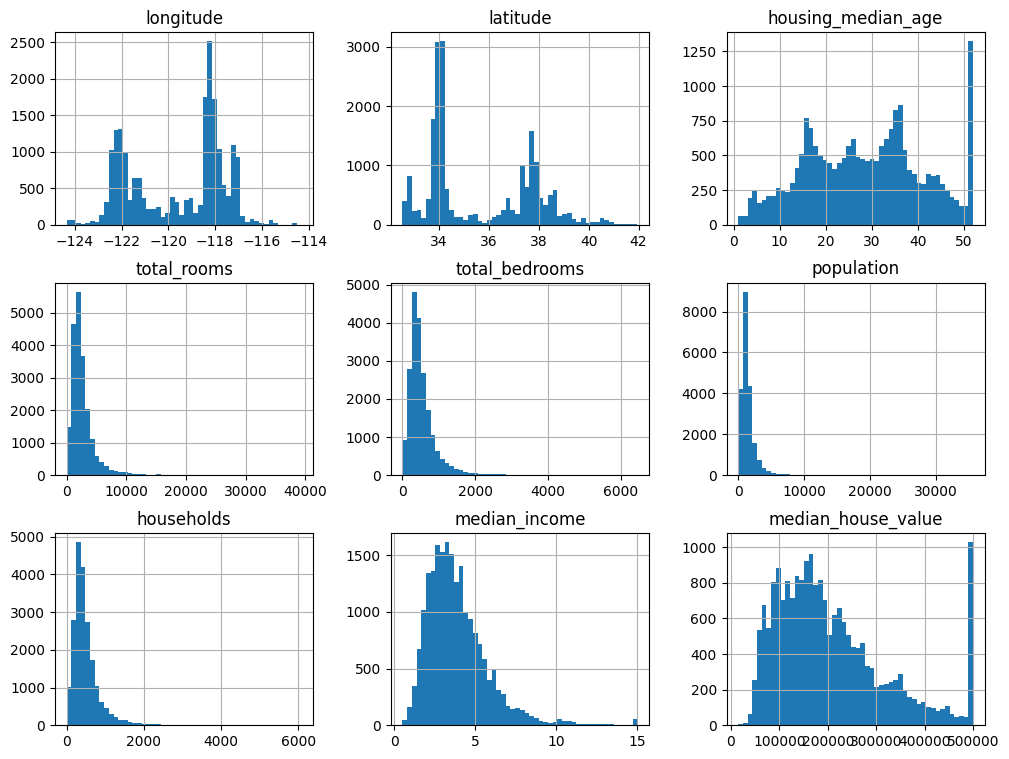

In [7]:
# plotting a histogram
housing_full.hist(bins = 50 , figsize = (12,9))
plt.show()
# in short bins is diving the column range by the amount we set of bins
# bins= 50 divides each column's own min-to-max range into 50 equal parts — separately, per column.

In [8]:
# now let's split the dataset
def shuffle_and_split_data(data , test_ratio , rng):
  # first create a list
  shuffled_indices = rng.permutation(len(data)) # generates a randomly shuffled list of numbers from 0 to len(data)-1
  # second create the test_set_size
  test_set_size = int(len(data) * test_ratio)
  # now make the train and test indices  so that we
  # can use this as a variable and use it in future , see forward cell
  test_indices = shuffled_indices[:test_set_size]
  train_indices = shuffled_indices[test_set_size:]


  # make sure u return the train_set and test_set that , coz it's a function
  return data.iloc[train_indices], data.iloc[test_indices]

In [9]:
rng = np.random.default_rng()
train_set , test_set = shuffle_and_split_data(housing_full , 0.2 , rng)


In [10]:
print(f"the length of the training set : {len(train_set)}")
print(f"the length of the testing set : {len(test_set)}")

the length of the training set : 16512
the length of the testing set : 4128


from here i skipped some code . future check again .

In [11]:
# to ensure that the test set will remain consistent across multiple runs,
# even if u refresh the dataset

from zlib import crc32
def is_id_in_test_set(identifier, test_ratio):
  return crc32(np.int64(identifier)) < test_ratio * 2**32

def split_data_with_id_hash(data , test_ratio , id_column):
  ids = data[id_column]
  in_test_set = ids.apply(lambda id_ : is_id_in_test_set(id_ , test_ratio))
  return data.loc[~in_test_set] , data.loc[in_test_set]


In [12]:
housing_with_id = housing_full.reset_index() # adds an 'index' column
train_set , test_Set = split_data_with_id_hash(housing_with_id, 0.2, "index")


In [13]:
housing_with_id["id"] = (housing_full["longitude"] * 1000 + housing_full["latitude"])
# longitude got * 1000 so that longitude dont overlap the latitude
housing_with_id.head(3)

,index,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,id
0,0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY,-122192.12
1,1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY,-122182.14
2,2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY,-122202.15


continue building and practicing

In [14]:
# now we just gonna see / checking out how to we be can split with
# the function instead of manual split which we just did  before

# so for this import the train_test_split function
from sklearn.model_selection import train_test_split

train_set , test_set = train_test_split(housing_full , test_size = 0.2 , random_state = 42)


#### using stratified sampling now instead of random sampling

because median income is important for predicting house prices , so instead of using the pure random sampling , we will use the `stratified sampling ` - but based on income groups .


* roblem: median_income is a continuous number (1.2, 3.7, 5.9, etc.) — you can't stratify on continuous values directly, because there'd be almost no two rows with the exact same income, so no real "groups" to sample proportionally from.

* Solution: This pd.cut() code creates the actual strata (groups) mentioned in the text — bucketing incomes into 5 categories:

In [15]:
# using an fn called pd.cut() for helping us to create an income category attribute with five categories
housing_full["income_cat"] = pd.cut(housing_full["median_income"],
                                   bins = [0, 1.5 , 3.0 , 4.5 , 6.0, np.inf], # last group is upto infinity
                                   labels = [1,2,3,4,5]) # labels for each group
# np.inf is numpy's infinity and here it means the last bin's value is 6 so from 6 to the highest available

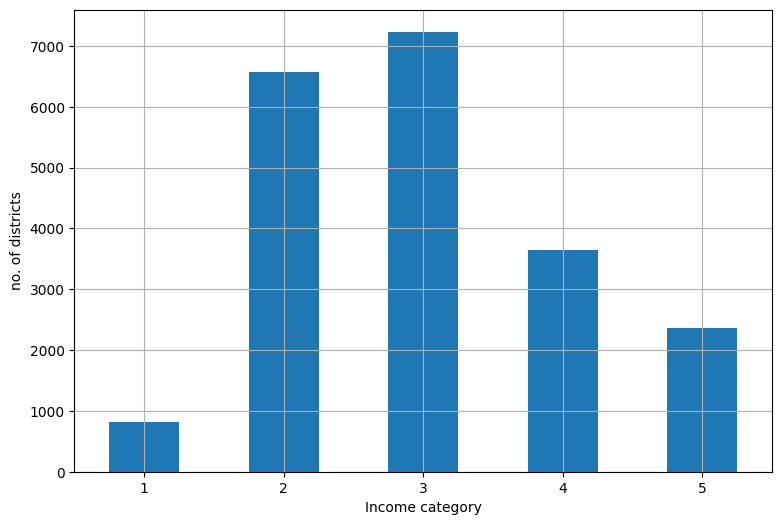

In [16]:
# representation of income categories
# s1 - create a variable that can return the category count in ascending order
# s1 - make sure we use the income_cat feature we just created because median _income was providing us the continous value
cat_counts = housing_full["income_cat"].value_counts().sort_index()

plt.figure(figsize =(9,6))

# s2 - now we need to plot a bar graph
cat_counts.plot.bar(rot = 0 , grid = True) # rot means rotation

plt.xlabel("Income category")
plt.ylabel("no. of districts")
plt.show()

* basically value_counts tells how many times a category is appeared so if it says 3 - 1200 that means 3 categories appeared that many times , 2 - 1229 , 2 different categories appeared this many(1229) times  etc.
but it return the highest to lowest count so

* we gonna use sort_index() to help us to return the result in ascending order .
*  rot kuch nahi bass numbers xlabel wale values kon horizonatl/vertical lekhna ka teraka hain

1. finally we can perform stratified sampling

* StratifiedShuffleSplit :- a splitter from sklearn.model_selection that combines `shuffling + stratified sampling`

* it randomly shuffles the data but keeps the proportion of each categroy (e.g income_cat both in train set and test set ).

In [17]:
# so now we want to perform StratifiedShuffleSplit which doesn't perform
# random sampling like train_test_split

from sklearn.model_selection import StratifiedShuffleSplit
splitter  = StratifiedShuffleSplit (n_splits = 10 ,
                                    test_size = 0.2 ,
                                    random_state = 42)
strat_splits = [] # empty list of store each of the 10 splits.
for train_index , test_index in splitter.split(housing_full,
                                               housing_full["income_cat"]):
  strat_train_set_n = housing_full.iloc[train_index]
  strat_test_set_n = housing_full.iloc[test_index]
  strat_splits.append([strat_test_set_n , strat_train_set_n])


* split() needs two arguments:

1. housing_full → the actual data to be split (what gets divided into train/test)

2. housing_full["income_cat"] → tells the splitter which column to stratify by (so it knows how to keep proportions equal)

In [18]:
# creation of the first split
strat_train_set , strat_test_set = strat_splits[0]

# so basically i just picked the first split and named the sets
# strat_train_set , strat_test_set from n sets we made, in short the 10 sets we made
# only using the first one for now

* there is one more shorter method to extract the first split , by using train_test_split method and
the train_test_split method provided us an argument called startify , which will work the same . so performing this now

In [19]:
## shorter way to create one split
strat_train_set , strat_test_set = train_test_split(housing_full , # which dataset to use
                                                    test_size = 0.2 ,
                                                    random_state = 42,
                                                    stratify = housing_full["income_cat"])
# for stratify remember first provdide the dataset , and then the feature the stratify needs to be performed.


In [20]:
# let's check if stratify is working perfectly or not
# lets check the income_cat proporations in the test set

print(strat_test_set["income_cat"].value_counts().sort_index() / len(strat_test_set))

print(housing_full["income_cat"].value_counts().sort_index() / len(housing_full))

# perfect the test set proportions looks identical to full dataset

income_cat
1    0.039971
2    0.318798
3    0.350533
4    0.176357
5    0.114341
Name: count, dtype: float64
income_cat
1    0.039826
2    0.318847
3    0.350581
4    0.176308
5    0.114438
Name: count, dtype: float64


Remember:

Stratified sampling check = compare test set % vs full dataset %, not test vs train directly.

If test mirrors the full dataset, train mirrors it too (by definition — they're complementary halves).

In [21]:
"""
Why: income_cat was never meant to be a real feature for your ML model —
you only created it as a temporary tool to enable stratified sampling. Once the split is done and
verified, you don't need it anymore, so you remove it from both sets.
"""

# so basically we gonna drop this income_cat feature ,
# because we are not gonna use it for the ml model ,
# but we learned how to split and use stratify when we need

# so let's write the code for dropping and removing this feature from main dataset(housing_full)

for set_ in (strat_train_set , strat_test_set):
  set_.drop("income_cat" , axis = 1 , inplace = True)


In [22]:
# making an copy of the original dataset ,
#so that we can perform some transformations and apply  methods to
#check whatever we want and our oirignal dataset will be stayed as it is

housing = housing_full.copy()

### visualizing  the dataset looks

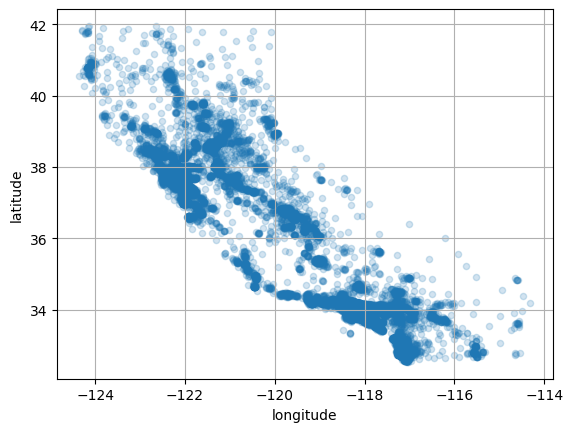

In [23]:
housing.plot(kind = "scatter",
             x = "longitude",
             y = "latitude",
             grid = True ,
             alpha = 0.2 ) # added alpha for better visualizing
plt.show()


This below image tells you that the housing prices are very much related to the location (e.g., close to the ocean) and to the
population density, as you probably knew already

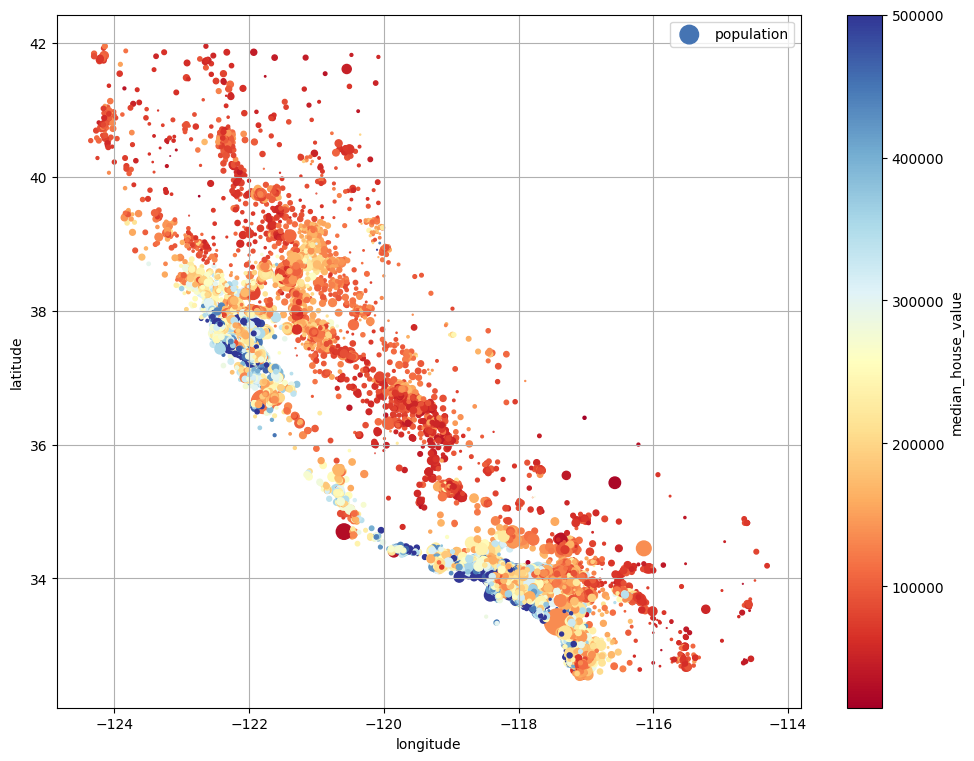

In [24]:
housing.plot(kind = "scatter",
             x = "longitude" ,
             y = "latitude",
             grid = True,
             s = housing["population"] / 100 ,
             label = "population",
             c = "median_house_value", cmap = plt.cm.RdYlBu , colorbar = True,
             legend = True , sharex = False , figsize = (12,9))
plt.show()

NEXT STEP - Now that train/test is split, we're exploring the training set to find patterns — specifically, which features are most related to the target (median_house_value) before building a model.

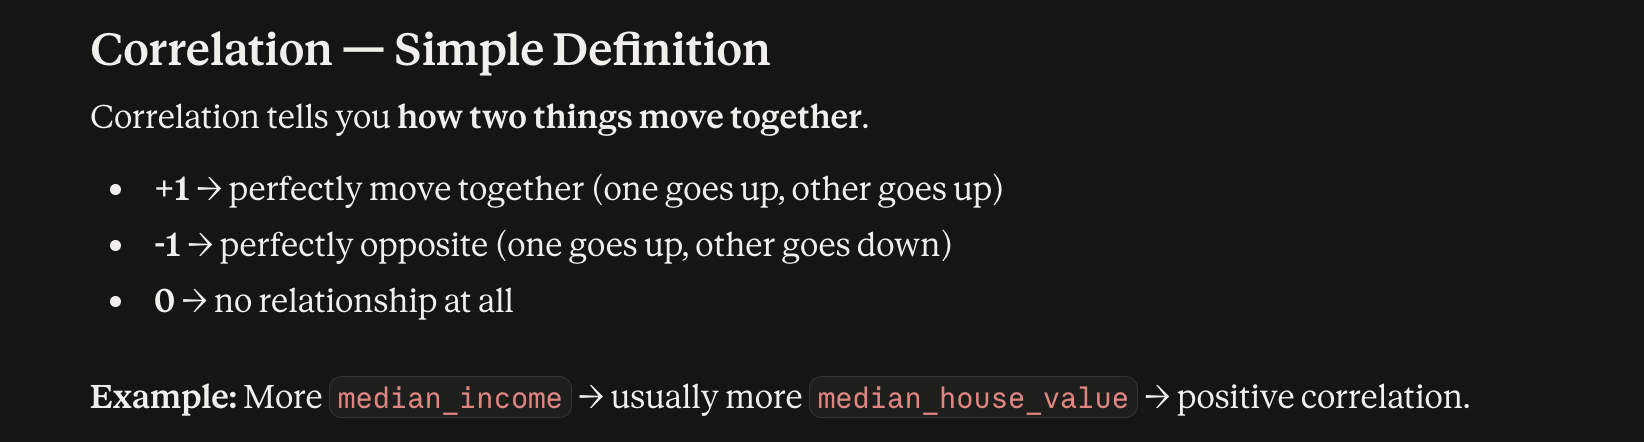

* so basically now we gonna check which features are the most related or important for making predictions .

* Note :- our output/target column is median_house_value


In [25]:
# so we created an correlation_matrix
correlation_matrix = housing.corr(numeric_only = True)

*  `.corr()` = is used to check all the correlation between every pair of numeric columns .

* numeric_only = True means only numeric columns / features are taken

In [26]:
# now u can look at how much attribute correlates with the median house value
correlation_matrix["median_house_value"].sort_values(ascending = False)
# correlation_matrix["median_house_value"] - pick only one column from that matrix
# and because we want to check correlations related to median_house_value , we will pick that
# sort_values(ascending = False) means sort results highes to lowest

,median_house_value
median_house_value,1.000000
median_income,0.688075
total_rooms,0.134153
housing_median_age,0.105623
households,0.065843
total_bedrooms,0.049686
population,-0.024650
longitude,-0.045967
latitude,-0.144160


* let's explore another way to check the correlation between attributes

* we will use a pandas method called `scatter_matrix() fn`.

* scatter matrix() fn helps with plotting every mumerical attribute against every other numerical attribute .

* there are 9 numerical  attributes so 9^2 = 81 plots will be generated but it will not fit the page , so we will only check on the promising attributes ,

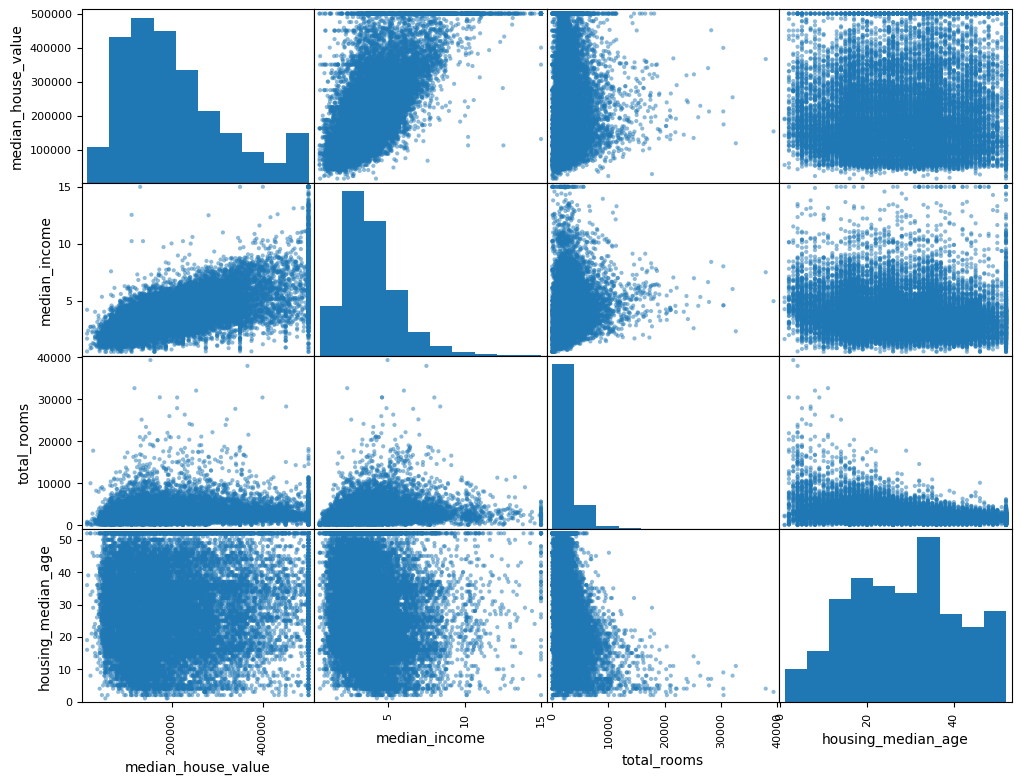

In [27]:
# now let's get this plot done

from pandas.plotting import scatter_matrix

attributes = ["median_house_value" , "median_income", "total_rooms" , "housing_median_age"]
scatter_matrix(housing[attributes], figsize = (12,9))
plt.show()

* we can see the most important correlation for median_house_value is median_income so we gonna focus on that for a while , let's plot it again .

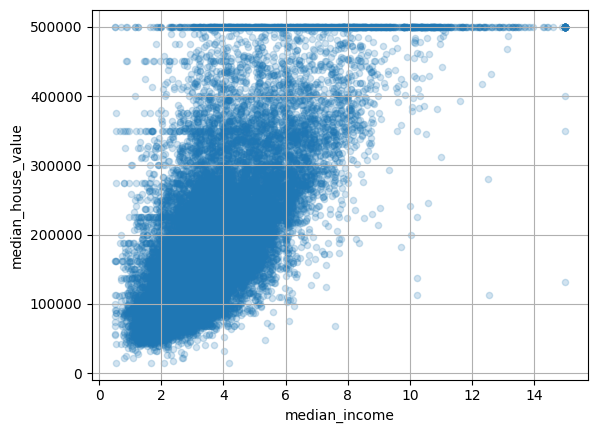

In [28]:
housing.plot(kind = "scatter" , x = "median_income" , y = "median_house_value" ,
             alpha = 0.2 , grid = True)
plt.show()

main step before training the model , is to check out what features we have and
what features we can add up so that model performs better , for eg instead of total rooms , we can create a new attribute/feature called rooms_per_house


So let's test out new features

In [29]:
# creating new features to check out
housing["rooms_per_house"] = housing["total_rooms"] / housing["households"]
housing["bedrooms_ratio"] = housing["total_bedrooms"] / housing["total_rooms"]
housing["people_per_house"] = housing["population"] / housing["households"]


* now lets check the correlation matrix again with new housing features .

In [30]:
# checking correlation matrix
# step-1 create an correlation_matrix for all the numeric features so that we can check the relations
correlation_matrix = housing.corr(numeric_only = True)
# step-2 now checking on our output feature that what features its mostly related to
correlation_matrix["median_house_value"].sort_values(ascending = False)


,median_house_value
median_house_value,1.000000
median_income,0.688075
rooms_per_house,0.151948
total_rooms,0.134153
housing_median_age,0.105623
households,0.065843
total_bedrooms,0.049686
people_per_house,-0.023737
population,-0.024650
longitude,-0.045967


* See the correlation matrix changed with new created/built  features.


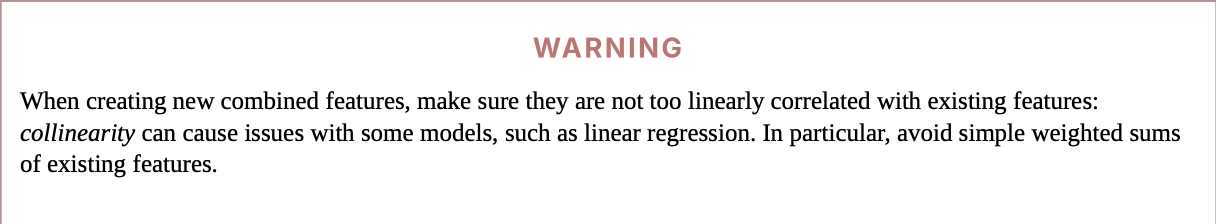

### Prepare the data before using ml algos

so far i had seen the split ways , did random sampling then startified sampling methods , different ways to split , then visualize the datasets , finding correlations , now gonna prepare the data for ml algos to perform on

* step-1 : let's seprate the predictors and the labels from strat_train_set , becuase we don't want to apply the sam transformations to the predictors and the target values .

In [31]:
# seprating the target values and the predictors ,
# so basically we are creating the x and the y officially now

# s1 - we gonna use our the dataset which we created from copying i.e housing
# s2 - now because we already split the dataset into two sets train and test
# s3 - we gonna remove the target feature /attribute from the training dataset
# so that we can use it in future

# creating X
housing = strat_train_set.drop("median_house_value" , axis = 1)

# creating y
# s4 - then we gonna copy the target feature and create the labels /taregted dataset , basically y
housing_labels = strat_train_set["median_house_value"].copy()


1. Note:-
* axis=1 = operate on columns (drop a column).

* axis=0 = operate on rows (drop a row).

Here it drops the median_house_value column, keeping all rows.

### 3. let's clean the data now

we gonna explore to some methods to clean the data , then pick one and then move forward

You can accomplish these easily using the Pandas DataFrame’s

*  dropna(),  
* drop(),
*  fillna() methods

let's apply them

In [32]:
# using the method dropna

# so basically here the method only removed the instances where total_bedrooms
# not that it removed the whole attribute from existence.

""" the code , u can run this just remove the notations / comment
housing.dropna(subset = ["total_bedrooms"] , inplace = True)
housing.head(2)
"""

# note : we not gonna use this method

' the code , u can run this just remove the notations / comment\nhousing.dropna(subset = ["total_bedrooms"] , inplace = True)\nhousing.head(2)\n'

In [33]:
# let's check another method drop()

# we just used this drop method to
# seprate our y (target values / attribite / label) from X
# and then created the housing(X) and housing_labels(y)


""" the code , u can run this just remove the notations / comment
housing.drop("total_bedrooms" , axis = 1, inplace = True)
housing.head(2)
"""

# note : we not gonna use this method

' the code , u can run this just remove the notations / comment\nhousing.drop("total_bedrooms" , axis = 1, inplace = True)\nhousing.head(2)\n'

In [34]:
# we gonna use this fillna() method with the use
# of median the mathematical median , Yes


# st1 is that we gonna pick the attribute total_bedrooms and
# then calculate median of that column and then store that value for future use
median = housing["total_bedrooms"].median()

# st2 is that  housing["total_bedrooms"].fillna(median) in this select that one column and then
# fill the empty places with the median value in housing["total_bedrooms"]
housing["total_bedrooms"] = housing["total_bedrooms"].fillna(median)


In [35]:
housing.head(1)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity
13096,-122.42,37.8,52.0,3321.0,1115.0,1576.0,1034.0,2.0987,NEAR BAY


Introducing the `SimpleImputer` ,

* Introducing the SimpleImputer because in above example we only added median values to one column ,and more especifically only in training set but

* We have to replace the missing values to median value not only in training set , but also the validation set , test set and any new data fed to the model

In [36]:
# let's use the SimpleImputer and for that
# let's create an instance as first step

# s1- import the class
from sklearn.impute import SimpleImputer

# s2 create an instance of the class
imputer = SimpleImputer(strategy = "median")
# here with the help of strategy (hyperparameter) set to median
# we can get the median value calculated and then ready to use

* Now if u remember , we did seprated the median_house_value , but here we are trying to clean or fix the dataset , by replacing the missing values with median but ,

* median can only work on numerical data(ofcourse) so we need to seprate the ocean_proximity feature because its not returning any numerical values

In [37]:
# let's create an copy of the data with only numerical attributes

housing_num = housing.select_dtypes(include = [np.number])

In [38]:
# now u can fit the  instance (imputer) to the
# training data using the fit() method
imputer.fit(housing_num)

SimpleImputer(strategy='median')

Now what happens is that instance we created has computed the median of each column/attribute/feature and then the result is stored in statistics_ instance varibale .

Note :-
1. Here in our dataset Only the total bedrooms attribute had missing values, but you cannot be sure that there won’t be any
missing values in new data after the system goes live, so it is safer to apply the imputer to all the numerical attributes:


In [39]:
# let's check what did the imputer remember?
imputer.statistics_

array([-118.51  ,   34.26  ,   29.    , 2125.    ,  434.    , 1167.    ,
        408.    ,    3.5385])

In [40]:
# let me independently double-check
# by computing it myself with plain pandas
housing_num.median().values

array([-118.51  ,   34.26  ,   29.    , 2125.    ,  434.    , 1167.    ,
        408.    ,    3.5385])

so we verified and proved check , now next step

Next Step - now we need to use this trained instance(imputer) to trasnform the training set by replacing the missing values with the learned medians .

In [41]:
X = imputer.transform(housing_num)
# remember? that housing num is the version of the dataset
# in which there are only numerical columns / features .


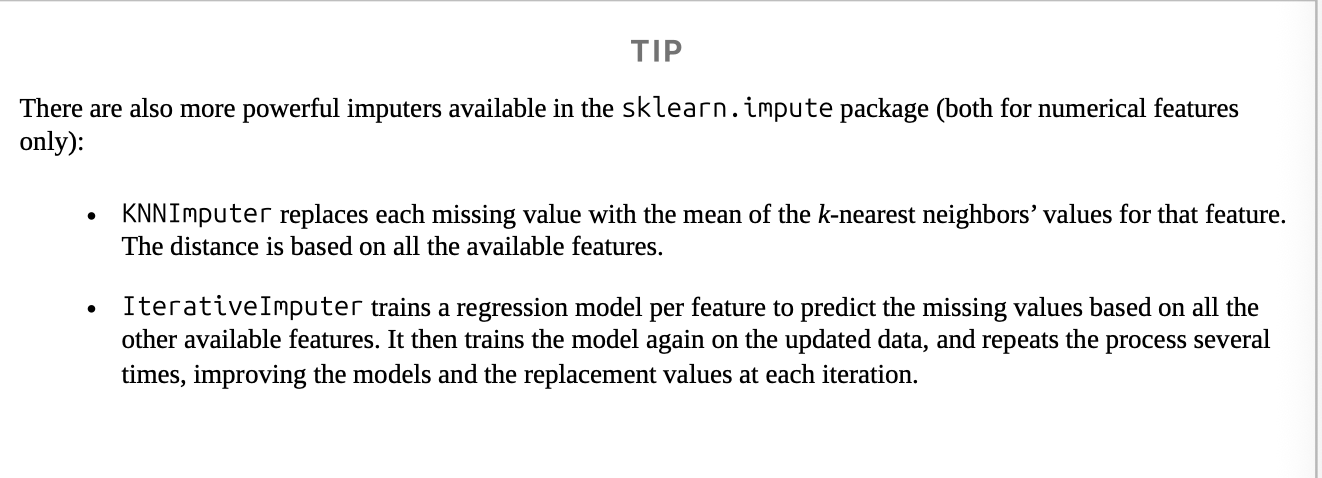

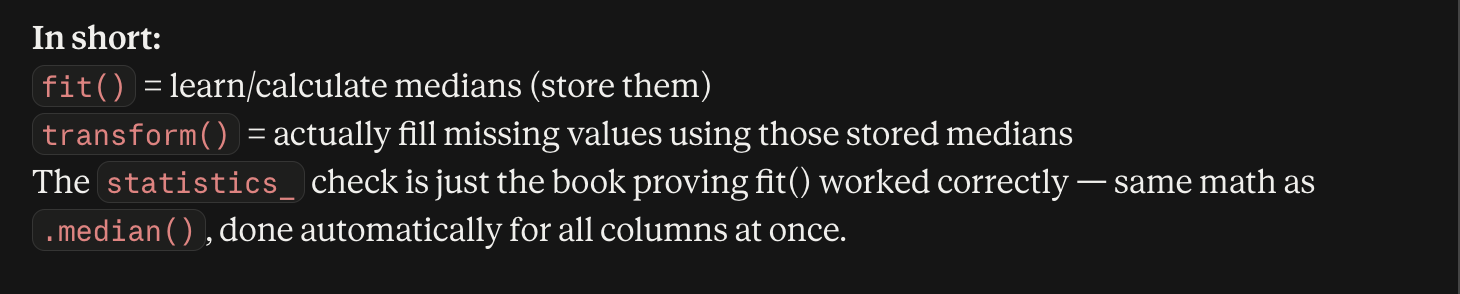

Teminologies :

1.  `Estimator` - any object that can learn from data using .fit()

* eg - imputer.fit(housing_full) -  imputer is an estimator , it "estimates the median values from data .

2.  `Transformer` - An estimator that can also transform data using .transform() ( basically change / convert it based on what it learned).

* eg - imputer.transform(housing_num) , so takes ur data and fills in missing values based on what it learned . Often combined as .fit_transform()

3.  `Predictor` - An estimator that can make predictions using .predict() (usually a trained ml model).

* eg - A trained `linear Regression` model - you feed it new data , and `.predict()` gives you predicted house prices .

4. `Inspection` - You can easily look inside any estimator to see what it learned - its parameters and learned values are accessible directly (no hidden secrets ).

* eg - imputer.statistics_ is you can inspect exactly what values the imputer learned, just by accessing that attribute.

5. `NonProliferation of classes` -  Instead of creating a new custom class for every tiny variation, scikit-learn keeps things simple: datasets are just NumPy arrays or pandas DataFrames/Series (not special custom objects), and settings are passed as plain strings/numbers.

* eg - strategy="median" — just a plain string, not some special Strategy class you'd need to import.

6. `Composition` - Complex tools are built by combining simple building blocks together , rather creating one giant complicated object .

* eg - A pipeline - you chain an imputer + a scaler + a model together , reusing simple existing pieces instead of writing one massive custom class that does everything.

7. `Sensible defaults` - Every parameter has a reasonable default value , so you can read often use a class without configuring anything, and only override what you actually need to change.

* eg - SimpleImputer() — you don't have to specify strategy; it defaults to "mean" if you leave it out.

Becuase we used .transform() method but now housing_num is an Numpy_Array so we need to convert this numpy array data back to pandas dataframe for further use , so let's create a new dataset but with no missing values(missing values got replaced by median) unlike housing_num

In [42]:
"""
X = imputer.transform(housing_num)
this line does't return a dataframe , instead returns a numpy array. so , now we need to convert our
dataset back to dataframe for use , let's understand how we can do it
"""
housing_tr = pd.DataFrame(X, columns  = housing_num.columns , index = housing_num.index)

# so basically now the new dataset we should use should be housing_tr becuase it filled all the missing values


* X → the actual numbers (now cleaned/imputed)

* columns=housing_num.columns → puts back the original column names (longitude, latitude, etc.)

* index=housing_num.index → puts back the original row labels/index

In [43]:
housing_tr.head(2)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income
13096,-122.42,37.80,52.0,3321.0,1115.0,1576.0,1034.0,2.0987
14973,-118.38,34.14,40.0,1965.0,354.0,666.0,357.0,6.0876


### Handling Text and Categorical Attributes


So far we only dealt with numerical attributes , so now
let's explore how to handle the text attribute(s) in a dataset like (OCEAN_PROXIMITY) , which is only text attribute for now in our dataset .

First step - let's pick the text column

* housing_cat = housing[["ocean_proximity"]] → picks out just the ocean_proximity column from housing, kept as a DataFrame (double brackets) so it's ready for encoding.

In [44]:
housing_cat = housing[["ocean_proximity"]] # Note:- ocean_proximity is an categorical attribute
housing_cat.head(8) # then let's check the first 8 rows

,ocean_proximity
13096,NEAR BAY
14973,<1H OCEAN
3785,INLAND
14689,INLAND
20507,NEAR OCEAN
1286,INLAND
18078,<1H OCEAN
4396,NEAR BAY


OK , time to explain the syntax
u notice the [[" "]] double brackets ,

* why ? becuase single `[" "]` bracket returns a Series ( 1D  , just values , no columns )

* and `[[" "]] `double bracket on the other hand returns a `DataFrame` (`2D₹ , and helps in keeping the column structure , even though its just one column )

Now it's time to perform encoding

### check out the encoding notes , given in our ML-Notes1

In [45]:
# let's test the original encoder type first
# but we will comment out this code cell why? check
# out the ML-Notes1 where I defined what encoding is

""" the code
from sklearn.preprocessing import OrdinalEncoder
ordinal_encoder = OrdinalEncoder()
housing_cat_encoded = ordinal_encoder.fit_transform(housing_cat)
"""

# Here’s what the first few encoded values in housing_cat_encoded look like:

"""  the code
housing_cat_encoded[:10]
"""

'  the code\nhousing_cat_encoded[:10]\n'

* we can also get a list of categories , using categories_

In [46]:
# let's check the categories

"""
ordinal_encoder.categories_
"""

'\nordinal_encoder.categories_\n'

now listen , lil bro - OrdinalEncoder is providing us the fake relationships so instead of using this we gonna check out the `OneHotEncoder`

In [47]:
# s1 - import OneHotEncoder , remember from sklearn library and it's preprocessing method
from sklearn.preprocessing import OneHotEncoder

# s2 - then create an instance
cat_encoder = OneHotEncoder()

# s3 - then create an varibale and combine that instance with the seprate
# column we made/picked from the full dataset
# s4 - perform .fit_transform ()
housing_cat_one_hot = cat_encoder.fit_transform(housing_cat)


Note:-  One-hot-encoder results by default as SciPy sparse matrix , instead of Numpy array so , lets see , to know what is sparse matrix check the Ml-Notes1

In [48]:
# Let's check out how sparse matrix looks like
print(housing_cat_one_hot[:2]) # first few rows


<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 2 stored elements and shape (2, 5)>
  Coords	Values
  (0, 3)	1.0
  (1, 0)	1.0


In [49]:
# for checking all the categories ,
# synatx - instance_name.categories_
cat_encoder.categories_

[array(['<1H OCEAN', 'INLAND', 'ISLAND', 'NEAR BAY', 'NEAR OCEAN'],
       dtype=object)]

In [50]:
print(housing_cat_one_hot[:4].toarray())

[[0. 0. 0. 1. 0.]
 [1. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0.]
 [0. 1. 0. 0. 0.]]


NOTE: There is one more way to get the output /result in the form of NumPy array , by setting sparse_output = False

Alternatively, you can set `sparse_output=False` when creating the OneHotEncoder, in which case the
transform() method will return a regular (dense) NumPy array directly:

In [51]:
from sklearn.preprocessing import OneHotEncoder

cat_encoder = OneHotEncoder(sparse_output= False)
# create an instance for OneHotEncoder and then set sparse_output = False

housing_cat_one_hot = cat_encoder.fit_transform(housing_cat)

# now a dense array

In [52]:
cat_encoder.categories_

[array(['<1H OCEAN', 'INLAND', 'ISLAND', 'NEAR BAY', 'NEAR OCEAN'],
       dtype=object)]

In [53]:
housing_cat_one_hot[:2]

array([[0., 0., 0., 1., 0.],
       [1., 0., 0., 0., 0.]])

In [54]:
# Let's visualize it in a better way
pd.DataFrame(housing_cat_one_hot[:4] , columns = cat_encoder.categories_)


,<1H OCEAN,INLAND,ISLAND,NEAR BAY,NEAR OCEAN
0,0.0,0.0,0.0,1.0,0.0
1,1.0,0.0,0.0,0.0,0.0
2,0.0,1.0,0.0,0.0,0.0
3,0.0,1.0,0.0,0.0,0.0


so , now lets check this. new way of comparison , which is very important ,

pandas has a function called `get_dummies` , which also convert categorical feature into a one-hot representantion , with one binary feature per category

* Think this in this way , that OneHotEncoder after applying .fit() has memory and it always outputs column(s) for every category it originally learned , even if some are missing from new data .

* But on the other hand , we can use get_dummies() , which does the same work like OneHotEncoder but if it produce same output then , why? using this , because few adv :-
1. has no memory , so basically it will create columns based on what's in the data currently .
2. imagine u get new data to work upon , now instead of using one-hot-encoder and get an output of all columns ,will be a waste ,especially when there are only 2 columns in new given data and we dont want to check other columns

In [55]:
# s1- creating an dataframe for the columns we want to compare
# synatx create a variable then use pd.DataFrame({"name_of_column" : ["categories_name"] })
testing = pd.DataFrame({"ocean_proximity" : ["INLAND" , "NEAR BAY"]})

# s2 - now let's visualize
pd.get_dummies(testing)


,ocean_proximity_INLAND,ocean_proximity_NEAR BAY
0,True,False
1,False,True


* Let's check out our cat_encoder ouputs when we make it transforms the same df_test ( using transform() , not fit_transform() ).


In [56]:
cat_encoder.transform(testing)

array([[0., 1., 0., 0., 0.],
       [0., 0., 0., 1., 0.]])

Let's test out get_dummies () on the unknown category , let's see if it can detect that or not

In [57]:
testing_unknown = pd.DataFrame({"ocean_proximity" : ["<2H OCEAN" , "ISLAND"]})
pd.get_dummies(testing_unknown)


,ocean_proximity_<2H OCEAN,ocean_proximity_ISLAND
0,True,False
1,False,True


BUT one-hot-encoder is smarter so it will detect the unknown category and raise an exception , if u prefer , u can set the handle_unknown (hyperparameter) = "ignore" , so it will result unknown category with zeros.

In [58]:
cat_encoder.handle_unknown = "ignore"
cat_encoder.transform(testing_unknown)

array([[0., 0., 0., 0., 0.],
       [0., 0., 1., 0., 0.]])

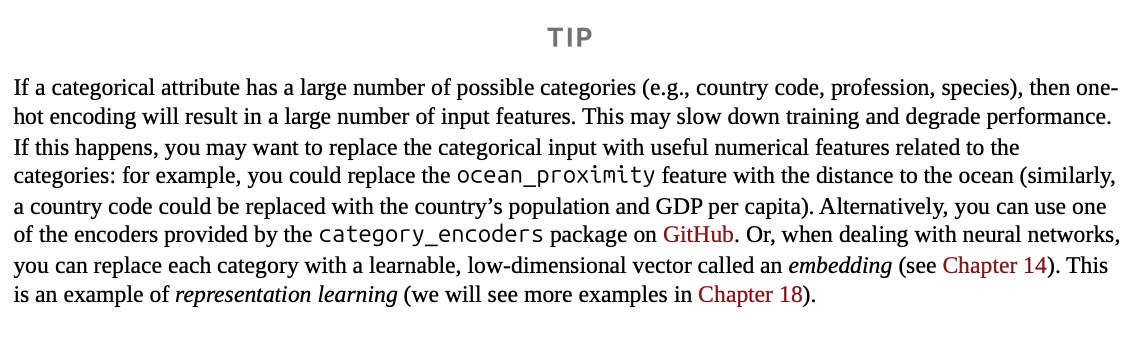

Ok , listen when we use the fit() and make an eastimator learn , it stores the column name(s) and they can be checked with the help of `feature_names_in_` attribute


In [59]:
# getting the name of the column /attribute/ categorical feature
cat_encoder.feature_names_in_

array(['ocean_proximity'], dtype=object)

* ₹ - transformers also provide a get_feature_names_out() method that u can use to build a DataFrame around the transformer's output.

in short u will get the column names and the categories associated with it.

In [60]:
# lets check out what we talked about
cat_encoder.get_feature_names_out()

array(['ocean_proximity_<1H OCEAN', 'ocean_proximity_INLAND',
       'ocean_proximity_ISLAND', 'ocean_proximity_NEAR BAY',
       'ocean_proximity_NEAR OCEAN'], dtype=object)

## Feature scaling transformation

why? well ml algos don't perform well when the numerical attrbutes have different scales.

In short the range of total no. of rooms is from 6 to 39,320 , but the median_income only ranges from 0 to 15

And most models will be biased toward ignoring the
median_income and will focus on no. of rooms and to avoid this there are two methods

1. `Min-Max scaling(normalization)` - Squeezes values into a `fixed range,usually 0 to 1`
* formula : scaled = ( x - min) / ( max - min )

2. `Standardization` - Centers data around mean = 0 , with standard deviation = 1 . `No fixed range` .
* formula : scaled = ( x - mean) / std

In [61]:
# ok now let's perform MinMaxScaler
from sklearn.preprocessing import MinMaxScaler

# S1 create an instance for the class
min_max_scaler = MinMaxScaler(feature_range = (-1, 1)) # ok so basically we using the range (-1 ,1)

# S2 and then connect with the instance with the method(.fit_transform) and the apply it on the dataset u want to
housing_num_min_max_scaled = min_max_scaler.fit_transform(housing_num)

min_max_scaler

MinMaxScaler(feature_range=(-1, 1))

In [62]:
print(f"Confirming shape : {housing_num_min_max_scaled.shape}")

Confirming shape : (16512, 8)


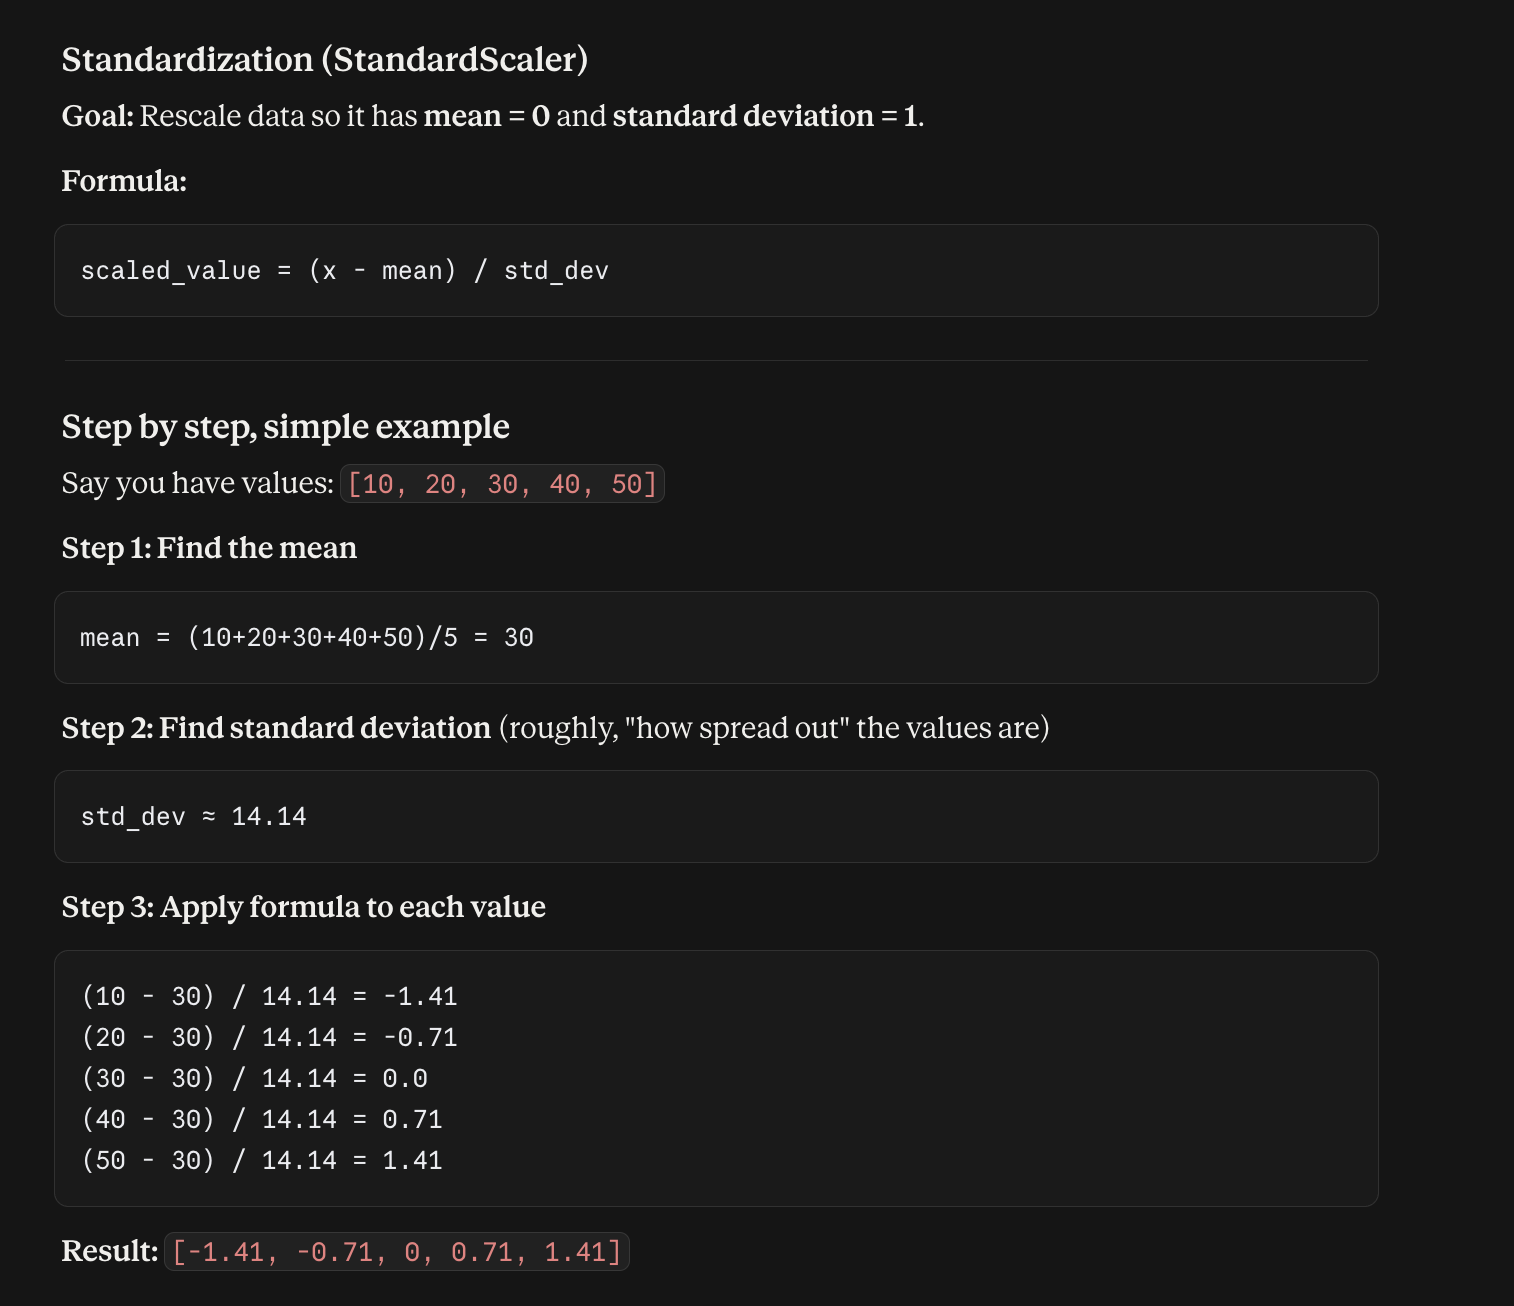

In [63]:
# Let's see what Standardization does
from sklearn.preprocessing import StandardScaler

std_scaler = StandardScaler()
housing_num_std_scaled = std_scaler.fit_transform(housing_num)

std_scaler

StandardScaler()

In [64]:
housing_num_std_scaled.shape

(16512, 8)

After normalization / standardization - `To Handle - tailed features` -

1. `First approach` $Heavy-tail fix$ (before scaling ):
* If a feature has a long tail (few extreme values , not exponentially rare )  
-> we should transform it first

* By using `square root` (or power between 0-1 ) for moderate tails .

* Use `log` for heavy tails (e.g. population -> log(population) becomes Gaussian / bell - shaped ).



2. `Second approach` - (alternative approach) $BUCKETIZING$

* It means chopping it's distribution into roughly equal-sized buckets and replacing each feature value with the index of the bucket it belongs to . (eg - like income_cat)

* `Advantage` - It results in near-uniform distribution
-> no further scaling needed .

3. `Multimodal features` (2+ peaks, e.g. housing_median_age):

* Option A: Bucketize + one-hot encode the buckets (treat as categories) → lets model learn different rules per range

* Option B: RBF (Radial Basis Function) – Measures how "close" a value is to a fixed target point, giving a similarity score (1 = identical, decaying toward 0 as it gets farther away).

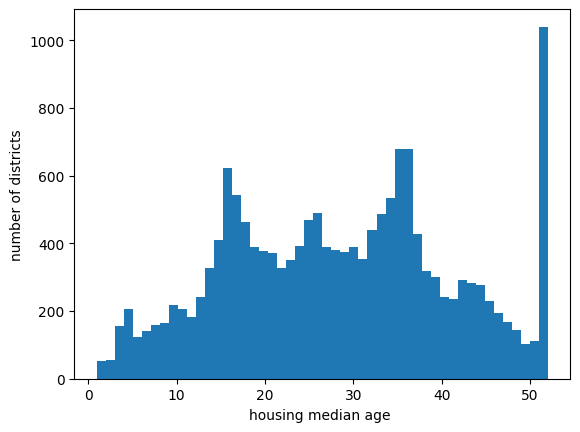

In [65]:
# plotting the graph for housing_median_age
plt.hist(housing["housing_median_age"] , bins = 50 )
plt.xlabel("housing median age ")
plt.ylabel("number of districts")
plt.show()

* termilogies

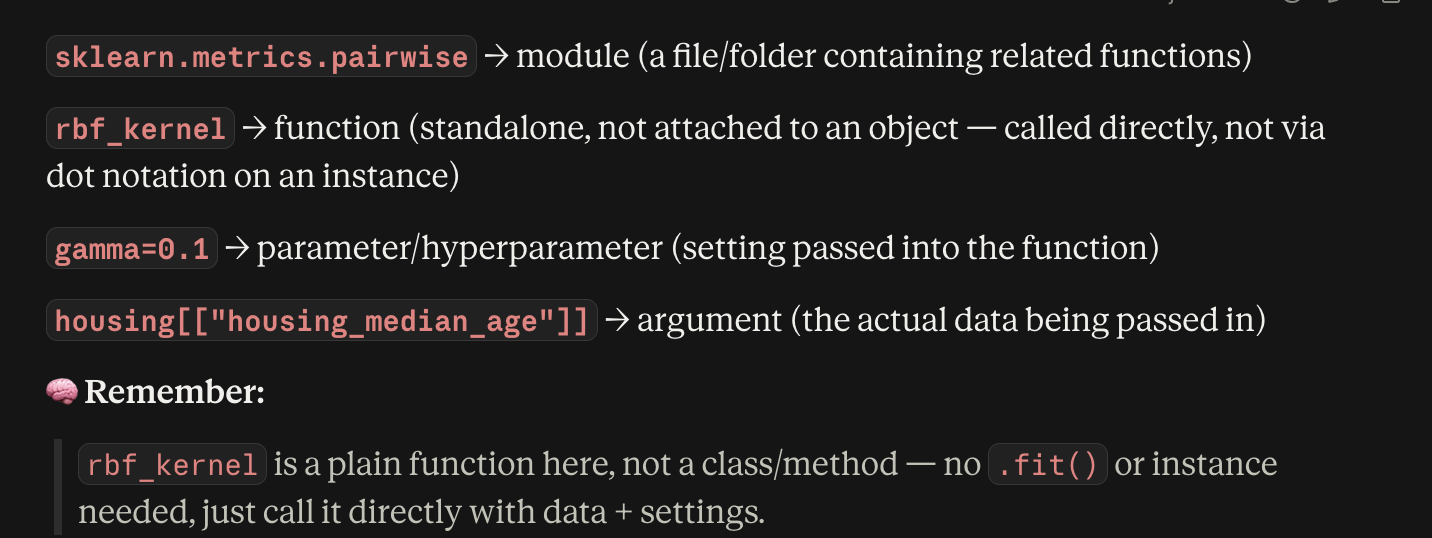

In [66]:
# Let's try rbf_kernel on housing_median_age becuase it has 2 tails

# s1 - import the rbf_kernel
from sklearn.metrics.pairwise import rbf_kernel

age_simil_35 = rbf_kernel(housing[["housing_median_age"]] , [[35]], gamma = 0.1)
# synatx -
# housing[["housing_median_age"]] - column on which have to check the similarity
# [[35]] -  fixed target point (means comparing with the age 35)
# gamma = 0.1 - how fast similarities should be decreasing if we go away from 35

print(age_simil_35)

# e-13, e-22 = scientific notation, means very small number (near zero).
# eg 6.70e-01 → 0.67 → very close to age 35

[[2.81118530e-13]
 [8.20849986e-02]
 [6.70320046e-01]
 ...
 [9.55316054e-22]
 [6.70320046e-01]
 [3.03539138e-04]]


In [67]:
housing.head(3)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity
13096,-122.42,37.80,52.0,3321.0,1115.0,1576.0,1034.0,2.0987,NEAR BAY
14973,-118.38,34.14,40.0,1965.0,354.0,666.0,357.0,6.0876,<1H OCEAN
3785,-121.98,38.36,33.0,1083.0,217.0,562.0,203.0,2.4330,INLAND


* After checking the similarity we will be creating a new feature column - and then will add it into the housing dataset (will add like we did it before when we created new ratio features for checking the correlation)

* `Advantage` - If age(35)districts price's pattern is different then model will create a new columnn and will learn pattern better ,

* Note - a raw number like 35 ,40 this doesn't provide that much clear patterns but giving how close to the numebr (35) is that is a better approach for calculation .

####  Note :-  So far we only focuse on the input features but we should also transform the output feature(s)

* Same concept if target has heavy tail - take log of it . But then model predicts log(price) , not actual price - need to apply exp() to convert it back .

* So to deal with it, will use `.inverse_transform`.

    Flow: Scale labels → train model on scaled labels → predict → use inverse_transform() to convert predictions back to original scale.

In [68]:
# lets  understand and test scaling for target

# s1 -import
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

# s2 - create an instance
target_scaler = StandardScaler()

# s3 - scaling the target , housing_labels = actual house price (y)
# .to_frame() -> converts Series into DataFrame (scaler needs 2D input)
scaled_labels = target_scaler.fit_transform(housing_labels.to_frame())

# s4 - Training model on scaled target
model = LinearRegression()

# Uses the full housing dataset's median_income column (all rows) to train the model.
model.fit(housing[["median_income"]] , scaled_labels)

# take 5 sample rows(pretending that its new data to test and make predictions on )
some_new_data = housing[["median_income"]].iloc[:5]
print(f"first 5 rows of median_income to stimulate new input (rows_index) (values) : {some_new_data}")

# s5 - making predictions (still in scaled form )
scaled_predictions = model.predict(some_new_data)
print(f"predictions but in scaled form {scaled_predictions}")

# s6 - convert back to real values
predictions = target_scaler.inverse_transform(scaled_predictions)
print(f"predictions after converting back to real price : {predictions}")

first 5 rows of median_income to stimulate new input (rows_index) (values) :        median_income
13096         2.0987
14973         6.0876
3785          2.4330
14689         2.2618
20507         3.5292
predictions but in scaled form [[-0.64466228]
 [ 0.80674175]
 [-0.52302364]
 [-0.5853166 ]
 [-0.12415952]]
predictions after converting back to real price : [[131997.15275877]
 [299359.35844434]
 [146023.37185694]
 [138840.33653057]
 [192016.61557639]]


target_scaler.fit_transform(housing_labels.to_frame())

* .fit() part → calculates the mean and standard deviation of housing_labels (the target values) — this is what StandardScaler needs to "learn" before it can scale anything

* .transform() part → actually applies the scaling formula (x - mean) / std using those learned values

In [69]:
housing_full.head(5)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,income_cat
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY,5
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY,5
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY,5
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY,4
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY,3


How about we check out an another way to do this scaling of target_labels , we can use `TrasnformedTargetRegressor`

    Flow -> Construct it -> give it the regresson model -> give the label transformer -> fit in on the training set (using the original unscalled labels.


* `Adv` - automatically use transformer for scaling the labels and train the regression model .

* `for prediction` - we will use regression model's predict() method , and use the scaler's inverse_transform() method .


So let's test it out

In [70]:
from sklearn.compose import TransformedTargetRegressor

model = TransformedTargetRegressor(LinearRegression(),
                                   transformer = StandardScaler())

model.fit(housing[["median_income"]] , housing_labels)

# prediction on the pretend data we choose in the last code cell
predictions = model.predict(some_new_data)

print(predictions)


[131997.15275877 299359.35844434 146023.37185694 138840.33653057
 192016.61557639]


### Custom transformers

It's for transformations that don't require any training , we can just write a function that takes a `NumPy array` as input and outputs the `transformed array` .

* `Creating an log transformer and apply it on the population feature`

In [71]:
# custom log transformer
from sklearn.preprocessing import FunctionTransformer

# log for transform and exponential for inverse_transform
log_transformer = FunctionTransformer(np.log , inverse_func = np.exp)

log_pop = log_transformer.transform(housing[["population"]])
log_pop[:10] # # first 10 rows, each value = log(original population)


,population
13096,7.362645
14973,6.501290
3785,6.331502
14689,7.520235
20507,7.555905
1286,6.542472
18078,6.232448
4396,7.620215
18031,7.886457
6753,7.371489


Difference between RBF (Radial Basis Function) Vs Gaussian RBF

* RBF - any fn that measures similarity based only on distance from a fixed point , closer means more similarity .

* Gaussian RBF - the most common type of RBF - uses the bell curve (Gaussian) formula specifically , so similarity decuays smoothly / exponentially as distance increases .

Formula: exp(-gamma * (x - target)^2)

* simple meaning


    If a point is very close to a refrence point -> similarity almmost = 1


    If a point is far away  -> similarity almost = 0 (drops off like a bell curve)

NOTE :-
* Bell curve means - both side equal , symmetrical

* Skewed - lopsided , one side has a longer tail than the other - not symmetrical.


In [72]:
# s1 - import the RBF function
from sklearn.metrics.pairwise import rbf_kernel
from sklearn.preprocessing import FunctionTransformer

# s2- create an instance and then wraps rbf_kernel so that it behaves like scikit-learn transformer
rbf_transformer = FunctionTransformer(rbf_kernel,
                                      kw_args = dict(Y = [[35]] , gamma = 0.1)) # taregt = 35 , decay_speed = 0.1

age_simil_35 = rbf_transformer.transform(housing[["housing_median_age"]])
print(f"Let's check out the similarity scores : {age_simil_35}")

# Full call becomes: rbf_kernel(X=housing_ages, Y=[[35]], gamma=0.1)
# Output: a similarity score (0 to 1) for each district, showing how close its age is to 35


Let's check out the similarity scores : [[2.81118530e-13]
 [8.20849986e-02]
 [6.70320046e-01]
 ...
 [9.55316054e-22]
 [6.70320046e-01]
 [3.03539138e-04]]


In [73]:
# let's check out our custome made rbf_transformer
rbf_transformer

FunctionTransformer(func=<function rbf_kernel at 0x79396d8d3ce0>,
                    kw_args={'Y': [[35]], 'gamma': 0.1})

`TBR`
1. `RBF kernel has no inverse` , At any distance from a point (except 0), there are always two possible values, so you can’t uniquely reverse it.

* In short : You can’t uniquely identify the original point just from the RBF similarity score, because many different points can have the same distance (and therefore the same score).


* eg - imagine a circle around and one landmarks is given , now two districts distance same (0.7) , so u cannot exactly tell which district it was , as there are many possibiliies , so `no inverse`

2.`rbf_kernel() does not look at features one-by-one`

* eg - If you give it 2 features (e.g. latitude + longitude), it calculates the combined 2D Euclidean distance to measure similarity.

`For Code Below` : We can't figure out based on same  distance but ,


here's how we can add a feature that will measure the geographic similarity between each district and San Francisco

Goal: Same RBF trick, but now measuring "how close is each district to San Francisco?" instead of comparing an age to 35.

In [74]:
# Example code for understanding
from sklearn.metrics.pairwise import rbf_kernel
from sklearn.preprocessing import FunctionTransformer

# Setting up a random coords , not pulled from dataset
sf_coords = 37.7293 , -122.41
sf_transformer = FunctionTransformer(rbf_kernel, # so whenever rbf_kernel is called pass the kw_args where y = sf_coords and X we hadn't given yet
                                     kw_args = dict(Y = [sf_coords] , gamma = 0.1)) # gamma means decay speed

sf_transformer
# kw_args stands for kewword arguments


FunctionTransformer(func=<function rbf_kernel at 0x79396d8d3ce0>,
                    kw_args={'Y': [(37.7293, -122.41)], 'gamma': 0.1})

In [75]:
# so it will calcualte with combining the latitude and longitude both
sf_simil = sf_transformer.transform(housing[["latitude" , "longitude"]])

print(f"Checking the similarity : {sf_simil[:10]}")

Checking the similarity : [[0.99949028]
 [0.05434528]
 [0.94339685]
 [0.01236998]
 [0.03396701]
 [0.88133079]
 [0.0430606 ]
 [0.98212641]
 [0.06423216]
 [0.0416599 ]]


`FunctionTransformer` - is a very handy , but what if you would like your  transformer to be trainable , learning some parameters in the fit() method and using them later in the transform() method? . So for this we need to write a custom class.

In [76]:
# let's create a class

# import base classes to make this behave like a real sklearn transformer
from sklearn.base import BaseEstimator, TransformerMixin
# helper functions to validate input data and check if .fit() was already called
from sklearn.utils.validation import check_array , check_is_fitted

# create a class for custom transformer
class StandardScalerClone(BaseEstimator , TransformerMixin):
  def __init__(self, with_mean = True): # constructor, sets with_mean hyperparameter
    self.with_mean = with_mean #store that setting on the instance

  def fit (self, X , y = None): # learning step (y=None since unsupervised, no target needed)
    self.mean_ = X.mean(axis = 0) # calculate mean per column, store it
    self.scale_ = X.std(axis = 0) # calculate std dev per column, store it
    self.n_features_in_ = X.shape[1] #remember how many columns/features were seen during fit

  # transformation step
  def transform(self, X):
    check_is_fitted(self) # error if .fit() wasn't called yet
    X = check_array(X) # validates X is proper numeric array format
    assert self.n_features_in_ == X.shape[1] # makes sure new data has same number of columns as training data
    # X.shape[1] here means 0 = rows , columns = 1
    if self.with_mean: # subtract mean (only if with_mean=True)
      X = X - self.mean_
    return X / self.scale_ # divide by std dev, return scaled result


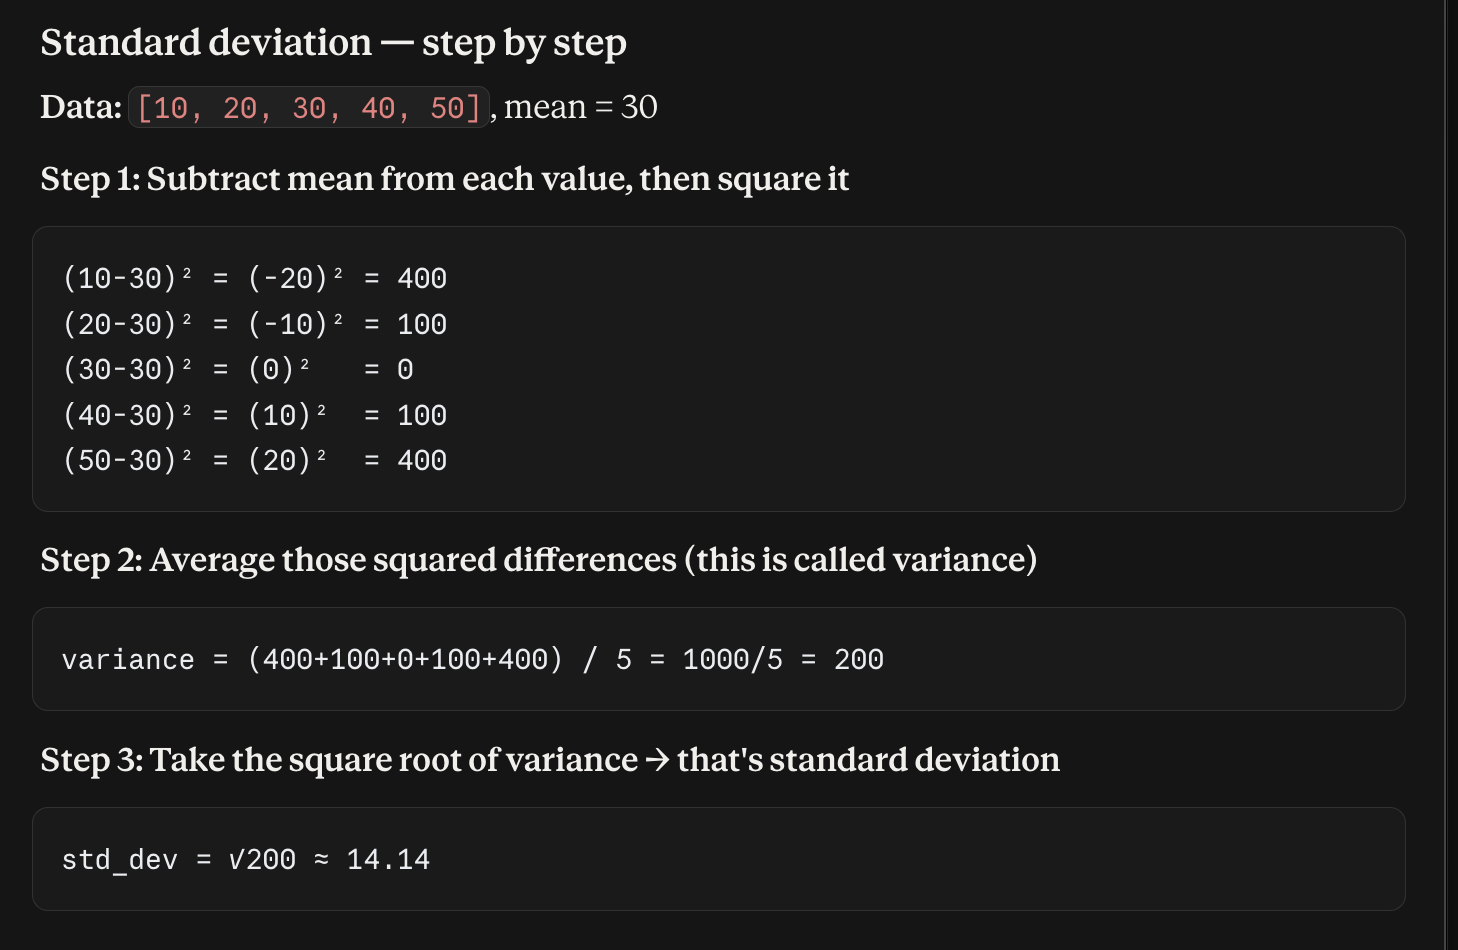

* Below code is a custom transformer that uses a KMeans cluster in the fit() method to identify the main clusters in the trainig data , and then uses rbf_kernel in the transform method to measure how similar each sample is to each cluster center

* Terminology:

1. KMeans → class (algorithm for clustering)
2. rbf_kernel → function

In [77]:
from sklearn.cluster import KMeans
from sklearn.base import BaseEstimator , TransformerMixin
from sklearn.utils.validation import check_array , check_is_fitted
from sklearn.metrics.pairwise import rbf_kernel

class ClusterSimilarity (BaseEstimator , TransformerMixin):
  def __init__(self, n_clusters = 10 , gamma = 1.0 , random_state = None):
    self.n_clusters = n_clusters
    self.gamma = gamma
    self.random_state = random_state

  def fit(self , X, y = None , sample_weight = None):
    # create a KMeans instance with our settings (n_clusters, random_state)
    self.kmeans_ = KMeans(self.n_clusters , random_state = self.random_state)
    # run KMeans on X to find cluster centers (learning step)
    self.kmeans_.fit(X , sample_weight = sample_weight)
    # sklearn convention: fit() must return self
    return self

  def transform (self, X):
    # for each row, measure similarity to each cluster center using RBF
    # (finds how close each row is to every cluster, not just the nearest one)
    return rbf_kernel(X, self.kmeans_.cluster_centers_ , gamma = self.gamma)

  def get_feature_names_out(self , names = None):
    # get_features_names_out returns readable names for the new columns this transformer creates
    # generate readable column names, one per cluster (e.g. "Cluster 0 similarity")
    return [f"Cluster {i} similarity "for i in range (self.n_clusters)]


sample_weight → optional, lets you give some rows more "importance" than others during clustering (e.g., weight by population).

y=None → KMeans is unsupervised, doesn't need labels/target — but sklearn's .fit() convention always expects a y parameter, so it's set to None as a placeholder (unused here).

names → placeholder parameter required by scikit-learn's convention for this method (expects input feature names), but not actually used here — set to None since it's ignored.

In [78]:
# Let's use this custom transformer and test it out

cluster_simil = ClusterSimilarity (n_clusters = 10 , gamma = 1.0 , random_state = 42)
similarities = cluster_simil.fit_transform(housing[["latitude" , "longitude"]])

cluster_simil


ClusterSimilarity(random_state=42)

The above code creates a ClusterSimilarity transformer,  It calls `fit_transform()` with the latitude and longitude of every district in the training set

The transformer uses k-means to locate the clusters,
then measures the Gaussian RBF similarity between each district and all 10 cluster centers. The result is a matrix with one row per district, and one column per cluster.

In [79]:
# checking similarities for the first row , comparing it wih all 10 cluster
similarities[:1].round(2)

array([[0.46, 0.  , 0.08, 0.  , 0.  , 0.  , 0.  , 0.98, 0.  , 0.  ]])

Alpha – Controls transparency of plotted points/shapes (0 = fully invisible, 1 = fully solid).

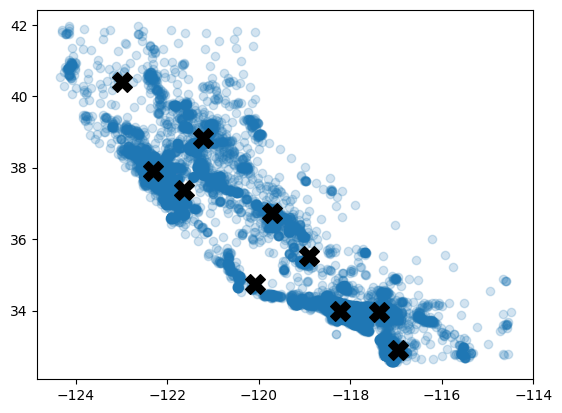

In [80]:
# let's visualize it with plot

plt.scatter (housing["longitude"] , housing["latitude"] , alpha = 0.2 ) # using alpha for better visualzation

plt.scatter (cluster_simil.kmeans_.cluster_centers_[:, 1],
             cluster_simil.kmeans_.cluster_centers_[:, 0],
             color = "black" , marker = "X" , s = 200 )

plt.show()

* cluster_centers_[:, 1] = longitude column of centers

* cluster_centers_[:, 0] = latitude column of centers

* s=200 = marker size

Graph: Light blue dots = California districts (map shape, denser = more overlapping points). Black X's = 10 cluster centers KMeans found — sitting right in the middle of dense population areas (like LA, SF regions)

## Transformation Pipelines

Ok in-short Scikit-learn provides the pipline class to help with creation of such sequences of transformations .
Let's test it out

Imputer – Fills in missing (NaN) values in your data, using a strategy like median, mean, or most frequent value.

In [81]:
# pipeline For numerical attributes ,
# which will first impute then scale input features

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

num_pipeline = Pipeline([
    ("impute" , SimpleImputer(strategy = "median")),
    ("standardize" , StandardScaler())
])

num_pipeline

Pipeline(steps=[('impute', SimpleImputer(strategy='median')),
                ('standardize', StandardScaler())])

This pipeline constructor takes a list of name/estimator pairs(2-tuples)
defining a sequence of steps .

NOTE - The names can be
anything you like, as long as they are unique and don’t contain double underscores (__). They will be useful later, when
we discuss hyperparameter tuning. The estimators must all be transformers (i.e., they must have a `fit_transform()`
method), except for the last one, which can be anything: a transformer, a predictor, or any other type of estimator.

In [82]:
# For no name , we can use make_pipeline fn , let's test it out
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

num_pipeline = make_pipeline (SimpleImputer(strategy = "median") , StandardScaler())
num_pipeline


Pipeline(steps=[('simpleimputer', SimpleImputer(strategy='median')),
                ('standardscaler', StandardScaler())])

* note :- If multiple transformers have the same name, an index is appended to their names (e.g., "foo-1"
,
"foo-2", etc.).

In [83]:
# let's use it on our numerical dataset
housing_num_prepared = num_pipeline.fit_transform(housing_num)

housing_num_prepared[:1].round(2) # checking on the first row


array([[-1.42,  1.01,  1.86,  0.31,  1.37,  0.14,  1.39, -0.94]])

As you saw earlier, if you want to recover a nice DataFrame, you can use the pipeline’s  ` get_feature_names_out()` method

In [84]:
df_housing_num_prepared = pd.DataFrame(
    housing_num_prepared ,
    columns = num_pipeline.get_feature_names_out(),
    index = housing_num.index
)

# df_housing_num_prepared.head(2) # run this to see the result

## `COLUMN TRANSFORMER`  

- in short , we saw how to handle categorical column(s) , and the numerical columsn seperately ,

* Let's create a single transformer handling /containing all columns , and applying appropiate transformations to each columns .

`Steps`

1. Import the ColumnTransformer class and all necessary fn(s) , algos etc.

2. Then define the list of numerical and categorical attributes / column names

3. construct pipelines for numerical and  categorical attributes.

4. Lastly construct a ColumnTransformer


NOTE:-  
* Constructor requires a list of triplets(3-tuples) , each containing a name (which must be unique) , a transformer , a list of names(or indices) of columns that the transformer should be applied on .

* names shouldn't contain the double underscores.

In [85]:
# using column transformer
from sklearn.compose import ColumnTransformer

# lets decide which features/atttributes we want to use
numerical_attributes = ["longitude" , "latitude" , "total_bedrooms" , "population",
                        "housing_median_age" , "median_income" , "households" ,"total_rooms"]

categorical_attributes = ["ocean_proximity"]

# creating the pipelines for both numerical data and categorical data
numerical_pipeline = make_pipeline(SimpleImputer(strategy = "median"),
                             StandardScaler())

categorical_pipeline = make_pipeline(SimpleImputer(strategy = "most_frequent"),
                                     OneHotEncoder(handle_unknown = "ignore"))


# ColumnTransformer = applies DIFFERENT pipelines to DIFFERENT columns,
# then combines all outputs into one final processed array.
# Each entry = (name, pipeline_to_apply, list_of_columns_it_applies_to)
preprocessing = ColumnTransformer([
    ("num" , num_pipeline , numerical_attributes),
    ("cat" , categorical_pipeline , categorical_attributes)
])

preprocessing

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('simpleimputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('standardscaler',
                                                  StandardScaler())]),
                                 ['longitude', 'latitude', 'total_bedrooms',
                                  'population', 'housing_median_age',
                                  'median_income', 'households',
                                  'total_rooms']),
                                ('cat',
                                 Pipeline(steps=[('simpleimputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehotencoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['ocean_proximity'])])

* we can use `drop` for particular column to be dropped if we dont want to specify the column names , so that those particular columns will remain unctouched .

* if want to handle those columns differently use  this `hyperparamter("passthrough")` to any transformer

`A BETTER APPROACH`

As listing all columns not that good idea , use `make_column_selector` class can help to automatically select all the features of a given type , such as numerical or categorical .


if don't care about transformers names either use `make_column_transformer()` ,similar to make_pipeline helps with names choosing

In [86]:
# let's try the better approach
from sklearn.compose import make_column_selector , make_column_transformer

numerical_pipeline = make_pipeline(SimpleImputer(strategy = "median"), StandardScaler())
categorical_pipeline = make_pipeline(SimpleImputer(strategy = "most_frequent") , OneHotEncoder(handle_unknown = "ignore"))


preprocessing = make_column_transformer(
    (numerical_pipeline , make_column_selector(dtype_include = np.number)),
    (categorical_pipeline , make_column_selector(dtype_include = object))
)

preprocessing

ColumnTransformer(transformers=[('pipeline-1',
                                 Pipeline(steps=[('simpleimputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('standardscaler',
                                                  StandardScaler())]),
                                 <sklearn.compose._column_transformer.make_column_selector object at 0x79396704d940>),
                                ('pipeline-2',
                                 Pipeline(steps=[('simpleimputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehotencoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 <sklearn.compose._column_transformer.make_column_selector object at 0x793966da9a90>)])

`NEXT STEP`
AFTER CREATION OF PIPELINE


Now applying the FULL preprocessing pipeline (both num + cat branches) to the actual housing features (X) in one single call.


* fit_transform() does two things at once:
1. fit()      -> learns medians, means/stds, categories, cluster centers etc.
from THIS data
2. transform() -> actually applies all those learned steps and   

In [87]:
housing_prepared = preprocessing.fit_transform(housing)

print(f"shape of housing_prepared : " , housing_prepared.shape)
housing_prepared[:1].round(2)

# 16k instances and 13 features it says

shape of housing_prepared :  (16512, 13)


array([[-1.42,  1.01,  1.86,  0.31,  1.37,  0.14,  1.39, -0.94,  0.  ,
         0.  ,  0.  ,  1.  ,  0.  ]])

In [88]:
# let's convert processsed NumPy array back to DataFrame
df_housing_prepared = pd.DataFrame(
    housing_prepared, # the transformed data (values only, no labels yet)
    columns=preprocessing.get_feature_names_out(), # auto-fetch proper column names from the pipeline
    index=housing.index # restore original row index (so rows still match housing)
)

df_housing_prepared.head(1).round(2)

,pipeline-1__longitude,pipeline-1__latitude,pipeline-1__housing_median_age,pipeline-1__total_rooms,pipeline-1__total_bedrooms,pipeline-1__population,pipeline-1__households,pipeline-1__median_income,pipeline-2__ocean_proximity_<1H OCEAN,pipeline-2__ocean_proximity_INLAND,pipeline-2__ocean_proximity_ISLAND,pipeline-2__ocean_proximity_NEAR BAY,pipeline-2__ocean_proximity_NEAR OCEAN
13096,-1.42,1.01,1.86,0.31,1.37,0.14,1.39,-0.94,0.0,0.0,0.0,1.0,0.0


`NOTE`

* The OneHotEncoder returns a sparse matrix and the num_pipeline returns a dense matrix`.

* When there is a such a mix of sparse and dense matrices , the ColumnTransformer estimates the density of the final matrix ( the ratio of nonzero cells) and it returns a sparse matrix if the density is lowe than a given threshold ( by_default , sparse_threshold = 0.3).

`RECAP` - below

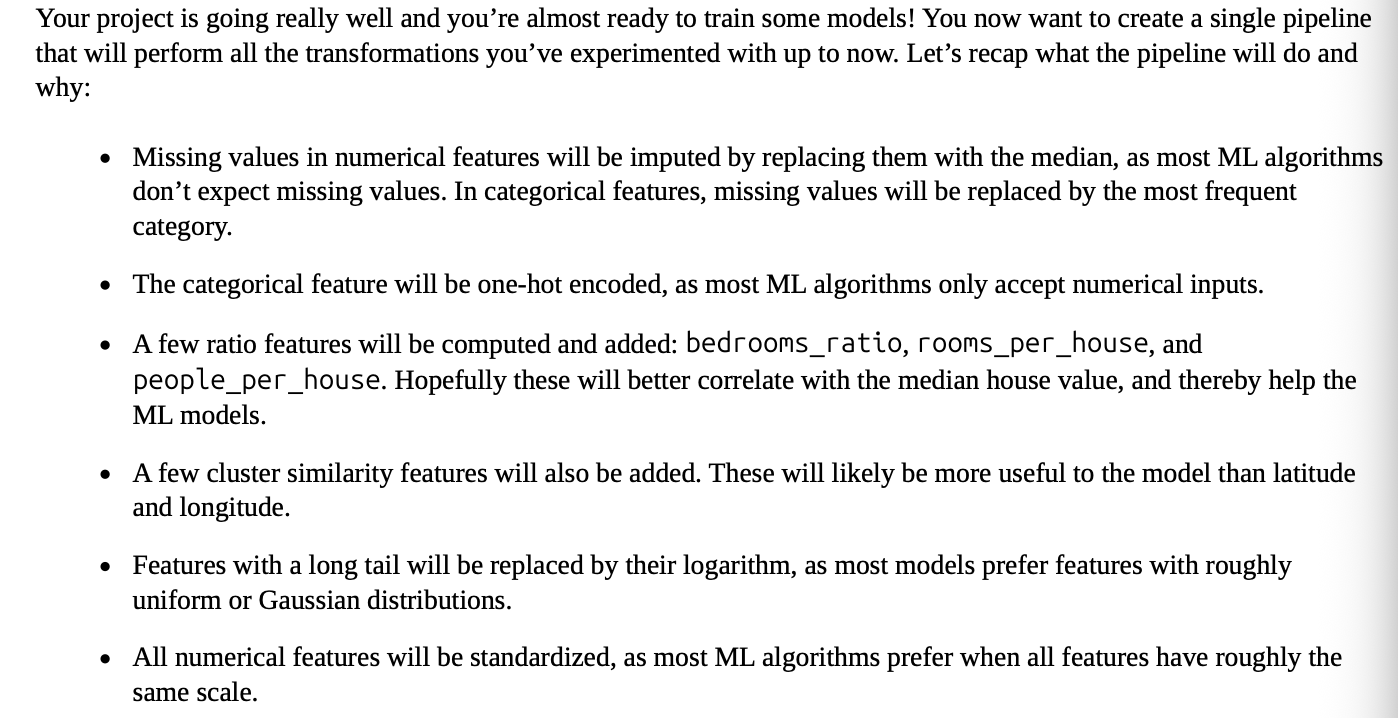

## Main code

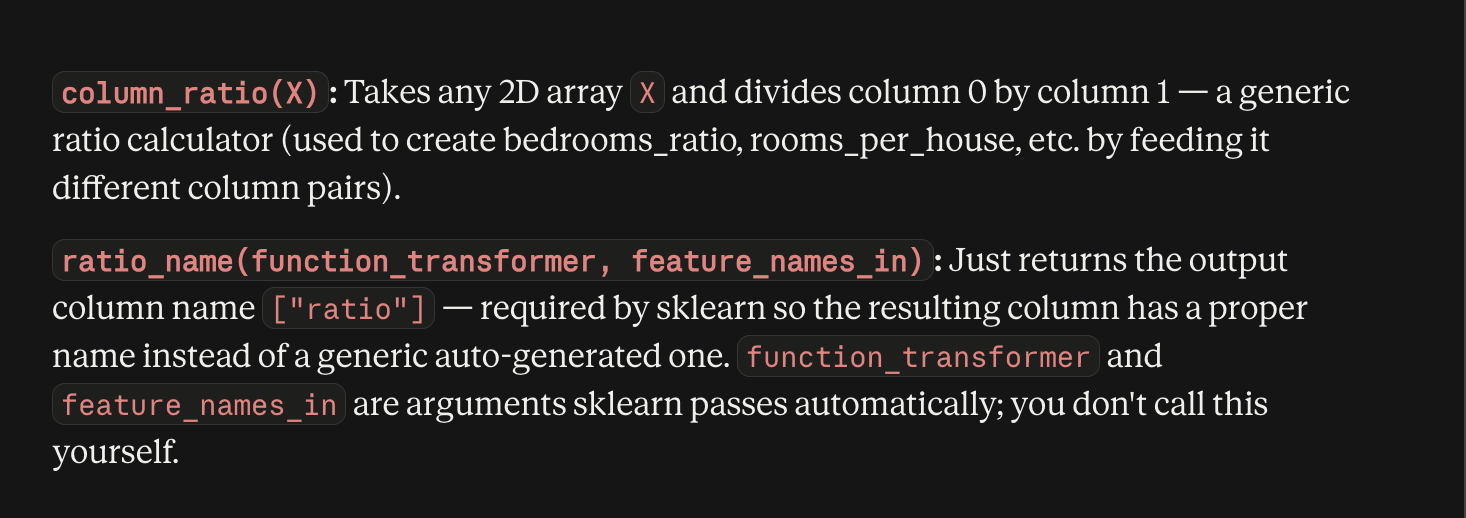

In [89]:
"""
from sklearn.cluster import KMeans
from sklearn.base import BaseEstimator , TransformerMixin
from sklearn.utils.validation import check_array , check_is_fitted
from sklearn.metrics.pairwise import rbf_kernel

class ClusterSimilarity (BaseEstimator , TransformerMixin):
  def __init__(self, n_clusters = 10 , gamma = 1.0 , random_state = None):
    self.n_clusters = n_clusters
    self.gamma = gamma
    self.random_state = random_state

  def fit(self , X, y = None , sample_weight = None):
    # create a KMeans instance with our settings (n_clusters, random_state)
    self.kmeans_ = KMeans(self.n_clusters , random_state = self.random_state)
    # run KMeans on X to find cluster centers (learning step)
    self.kmeans_.fit(X , sample_weight = sample_weight)
    # sklearn convention: fit() must return self
    return self

  def transform (self, X):
    # for each row, measure similarity to each cluster center using RBF
    # (finds how close each row is to every cluster, not just the nearest one)
    return rbf_kernel(X, self.kmeans_.cluster_centers_ , gamma = self.gamma)

  def get_feature_names_out(self , names = None):
    # get_features_names_out returns readable names for the new columns this transformer creates
    # generate readable column names, one per cluster (e.g. "Cluster 0 similarity")
    return [f"Cluster {i} similarity "for i in range (self.n_clusters)]
"""
print("code for review and use for refrence")
# this code is what we did earlier but here pasted for review , as it's being direclty used here


code for review and use for refrence


In [90]:
def column_ratio(X):
    return X[:, [0]] / X[:, [1]]  # divide column 0 by column 1 (generic ratio calculator)

def ratio_name(function_transformer, feature_names_in):
    return ["ratio"]  # names the output column "ratio"

def ratio_pipeline():
    return make_pipeline(
        SimpleImputer(strategy="median"), # fill missing values with median
        FunctionTransformer(column_ratio, feature_names_out=ratio_name),  # compute the ratio
        StandardScaler() # scale the ratio
    )

log_pipeline = make_pipeline(
    SimpleImputer(strategy="median"),# fill missing values with median
    FunctionTransformer(np.log, feature_names_out="one-to-one"),  # log-transform skewed columns
    StandardScaler() # scale the log values
)

cluster_simil = ClusterSimilarity(n_clusters=10, gamma=1, random_state=42)  # your custom geo-cluster transformer

default_num_pipeline = make_pipeline(
    SimpleImputer(strategy="median"), # fill missing values with median
    StandardScaler() # scale the values
)

preprocessing = ColumnTransformer([
    ("bedrooms", ratio_pipeline(), ["total_bedrooms", "total_rooms"]), # bedrooms/rooms ratio
    ("rooms_per_house", ratio_pipeline(), ["total_rooms", "households"]), # rooms per household
    ("people_per_house", ratio_pipeline(), ["population", "households"]), # people per household
    ("log", log_pipeline, ["total_bedrooms", "total_rooms", "population",
                            "households", "median_income"]), # log-transform skewed features
    ("geo", cluster_simil, ["latitude", "longitude"]), # geo similarity to 10 clusters
    ("cat", categorical_pipeline, make_column_selector(dtype_include=object))  # encode text columns
],
remainder=default_num_pipeline) # apply default (impute+scale) to any leftover column (housing_median_age)


In [91]:
preprocessing

ColumnTransformer(remainder=Pipeline(steps=[('simpleimputer',
                                             SimpleImputer(strategy='median')),
                                            ('standardscaler',
                                             StandardScaler())]),
                  transformers=[('bedrooms',
                                 Pipeline(steps=[('simpleimputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('functiontransformer',
                                                  FunctionTransformer(feature_names_out=<function ratio_name at 0x79396e295e40>,
                                                                      func=<function column_ratio...
                                 ['total_bedrooms', 'total_rooms', 'population',
                                  'households', 'median_income']),
                                ('geo',
                                 ClusterSimilarity(gamma=1, random_state=42),
                                 ['latitude', 'longitude']),
                                ('cat',
                                 Pipeline(steps=[('simpleimputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehotencoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 <sklearn.compose._column_transformer.make_column_selector object at 0x793966daa0d0>)])

In [92]:
housing_prepared = preprocessing.fit_transform(housing)
print(f" the shape of housing_prepared is {housing_prepared.shape}")
housing_prepared[:1].round(2)


 the shape of housing_prepared is (16512, 24)


array([[ 1.85, -0.87, -0.33,  1.32,  0.64,  0.46,  1.31, -1.07,  0.46,
         0.  ,  0.08,  0.  ,  0.  ,  0.  ,  0.  ,  0.98,  0.  ,  0.  ,
         0.  ,  0.  ,  0.  ,  1.  ,  0.  ,  1.86]])

In [93]:
# lets get the list of all the columns we have now (all 24)

print(f"All columns/features names : {preprocessing.get_feature_names_out()}")

All columns/features names : ['bedrooms__ratio' 'rooms_per_house__ratio' 'people_per_house__ratio'
 'log__total_bedrooms' 'log__total_rooms' 'log__population'
 'log__households' 'log__median_income' 'geo__Cluster 0 similarity '
 'geo__Cluster 1 similarity ' 'geo__Cluster 2 similarity '
 'geo__Cluster 3 similarity ' 'geo__Cluster 4 similarity '
 'geo__Cluster 5 similarity ' 'geo__Cluster 6 similarity '
 'geo__Cluster 7 similarity ' 'geo__Cluster 8 similarity '
 'geo__Cluster 9 similarity ' 'cat__ocean_proximity_<1H OCEAN'
 'cat__ocean_proximity_INLAND' 'cat__ocean_proximity_ISLAND'
 'cat__ocean_proximity_NEAR BAY' 'cat__ocean_proximity_NEAR OCEAN'
 'remainder__housing_median_age']


## SELECT AND TRAIN A MODEL


At last! You framed the problem, you got the data and explored it, you sampled a training set and a test set, and you wrote
a preprocessing pipeline to automatically clean up and prepare your data for machine learning algorithms. You are now
ready to select and train a machine learning model.

### 6.1 Train and Evaluate on the Training Set

* training a very basic linea regression model to get started :

In [94]:
from sklearn.linear_model import LinearRegression

lin_reg = make_pipeline(preprocessing , LinearRegression())
lin_reg.fit(housing, housing_labels)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(remainder=Pipeline(steps=[('simpleimputer',
                                                              SimpleImputer(strategy='median')),
                                                             ('standardscaler',
                                                              StandardScaler())]),
                                   transformers=[('bedrooms',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('functiontransformer',
                                                                   FunctionTransformer(feature_names_out=<function ratio_name at 0x793...
                                                   'median_income']),
                                                 ('geo',
                                                  ClusterSimilarity(gamma=1,
                                                                    random_state=42),
                                                  ['latitude', 'longitude']),
                                                 ('cat',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehotencoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x793966daa0d0>)])),
                ('linearregression', LinearRegression())])

In [95]:
# Model is ready , let's check it on our training set

housing_predictions = lin_reg.predict(housing)

print(f" Model's predicted prices {housing_predictions[:8].round(2)}")

 Model's predicted prices [245970.16 372738.07 135706.8   91440.93 330873.54 212166.49 313698.39
 320299.1 ]


In [96]:
print(f"Model's actual prices {housing_labels[:8].values.round(2)}")


Model's actual prices [458300. 483800. 101700.  96100. 361800.  92600. 349300. 440900.]


Well, it works, but not always: the first prediction is way off (by over $200,000!), while the other predictions are better:
two are off by about 25%, and two are off by less than 10%. Remember that you chose to use the RMSE as your
performance measure, so you want to measure this regression model’s RMSE on the whole training set using Scikit-
Learn’s `root_mean_squared_error() `function:

In [97]:
# RMSE is the predictor
# RMSE compares ACTUAL vs PREDICTED to measure how wrong the model is —
# it NEEDS both actual and predicted values, not predictions alone

from sklearn.metrics import root_mean_squared_error

lin_rmse = root_mean_squared_error(housing_labels , housing_predictions)
lin_rmse

68972.88910758484

* The number 68972.89 means
model's predictions are, on average, off by about $68,973 from actual house prices.

*  Given that house prices in this dataset range roughly $50,000–$500,000+, an error of ~$69k is quite large — meaning this basic Linear Regression model isn't performing well yet (matches what you saw earlier: 246000 predicted vs 458300 actual).

`TIP`

We’re not using the `score()` method here because it returns the `R^2` coefficient of determination instead of the
RMSE. This `coefficient` represents the `ratio of the variance` in the data that the model can explain:

NOTE: the closer to 1
(which is the max value), the better.

If the model simply predicts the mean all the time, it does not explain any part of
the variance, so the model’s R2 score is 0. And if the model does even worse than that, then its R2 score can be
negative, and indeed arbitrarily low.

NOTE

* Error we got of 68k Dollars and the most median_housing_values of most districts range between
120k and 265k dollars so this much error is not good , and here this is an example of `underfitting` the training data .

* When this happens it can mean that the features do not provide enough information
to make good predictions, or that the model is not powerful enough.


`FIXES FOR UNDERFITTING`

* select a more powerful model, to feed the training algorithm with better features, or to reduce the
constraints on the model.

TESTING A POWERFULL MODEL , `DecisionTreeRegressor`

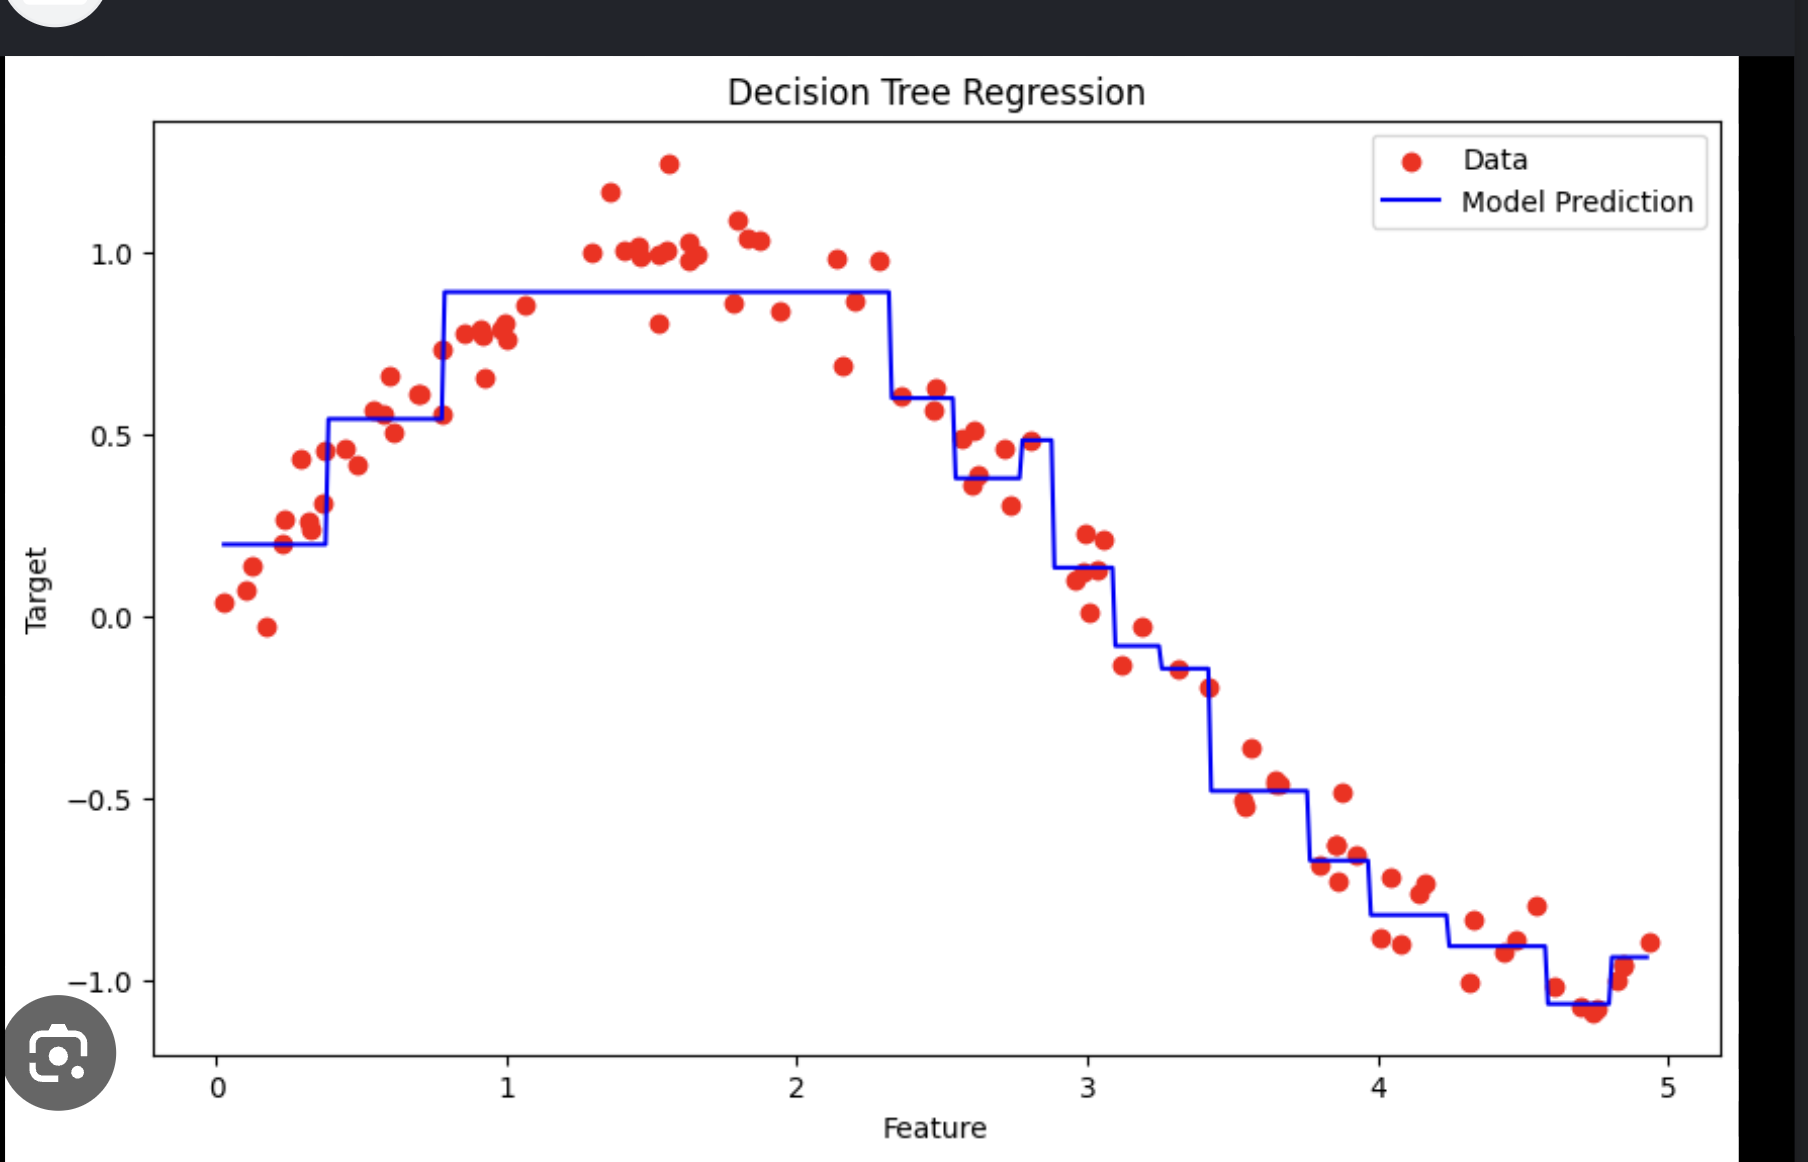

In [98]:
from sklearn.tree import DecisionTreeRegressor
tree_reg = make_pipeline(preprocessing , DecisionTreeRegressor(random_state = 42))
tree_reg.fit(housing ,housing_labels)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(remainder=Pipeline(steps=[('simpleimputer',
                                                              SimpleImputer(strategy='median')),
                                                             ('standardscaler',
                                                              StandardScaler())]),
                                   transformers=[('bedrooms',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('functiontransformer',
                                                                   FunctionTransformer(feature_names_out=<function ratio_name at 0x793...
                                                  ClusterSimilarity(gamma=1,
                                                                    random_state=42),
                                                  ['latitude', 'longitude']),
                                                 ('cat',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehotencoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x793966daa0d0>)])),
                ('decisiontreeregressor',
                 DecisionTreeRegressor(random_state=42))])

In [99]:
# let's evaluate on the training set like we did before
housing_predictions = tree_reg.predict(housing)
print(f"Model's predicted values are : {housing_predictions[:10].round(2)}")
print(f"Model's actual values are : {housing_labels[:10].values.round(2)}")

Model's predicted values are : [458300. 483800. 101700.  96100. 361800.  92600. 349300. 440900. 160100.
 183900.]
Model's actual values are : [458300. 483800. 101700.  96100. 361800.  92600. 349300. 440900. 160100.
 183900.]


* No error at all ?

In [100]:
# checking what is going on with rmse like we did earlier

tree_rmse = root_mean_squared_error(housing_labels, housing_predictions)
tree_rmse

0.0

To confirm that whether the model did overfit the data or it's correctly/perfectly predicting , Let's try evaluating using `cross-validation`

* NOTE : we doing cross-validation because we cant predict on test set so to confirm everything we can use cross-validation

## Better evaluation using cross-validation

* One way to evaluate the decision tree model would be to use the `train_test_split() `function to split the training
set into a smaller training set and a validation set, then train your models against the smaller training set and evaluate
them against the validation set. It’s a bit of effort, but nothing too difficult, and it would work fairly well.


* A great alternative is to use Scikit-Learn’s `k-fold cross-validation feature.` You split the training set into k nonoverlapping
subsets called `folds`, then you train and evaluate your model `k times`, picking a different fold for evaluation every time
(i.e., the validation fold) and using the other k – 1 folds for training. This process produces k evaluation scores

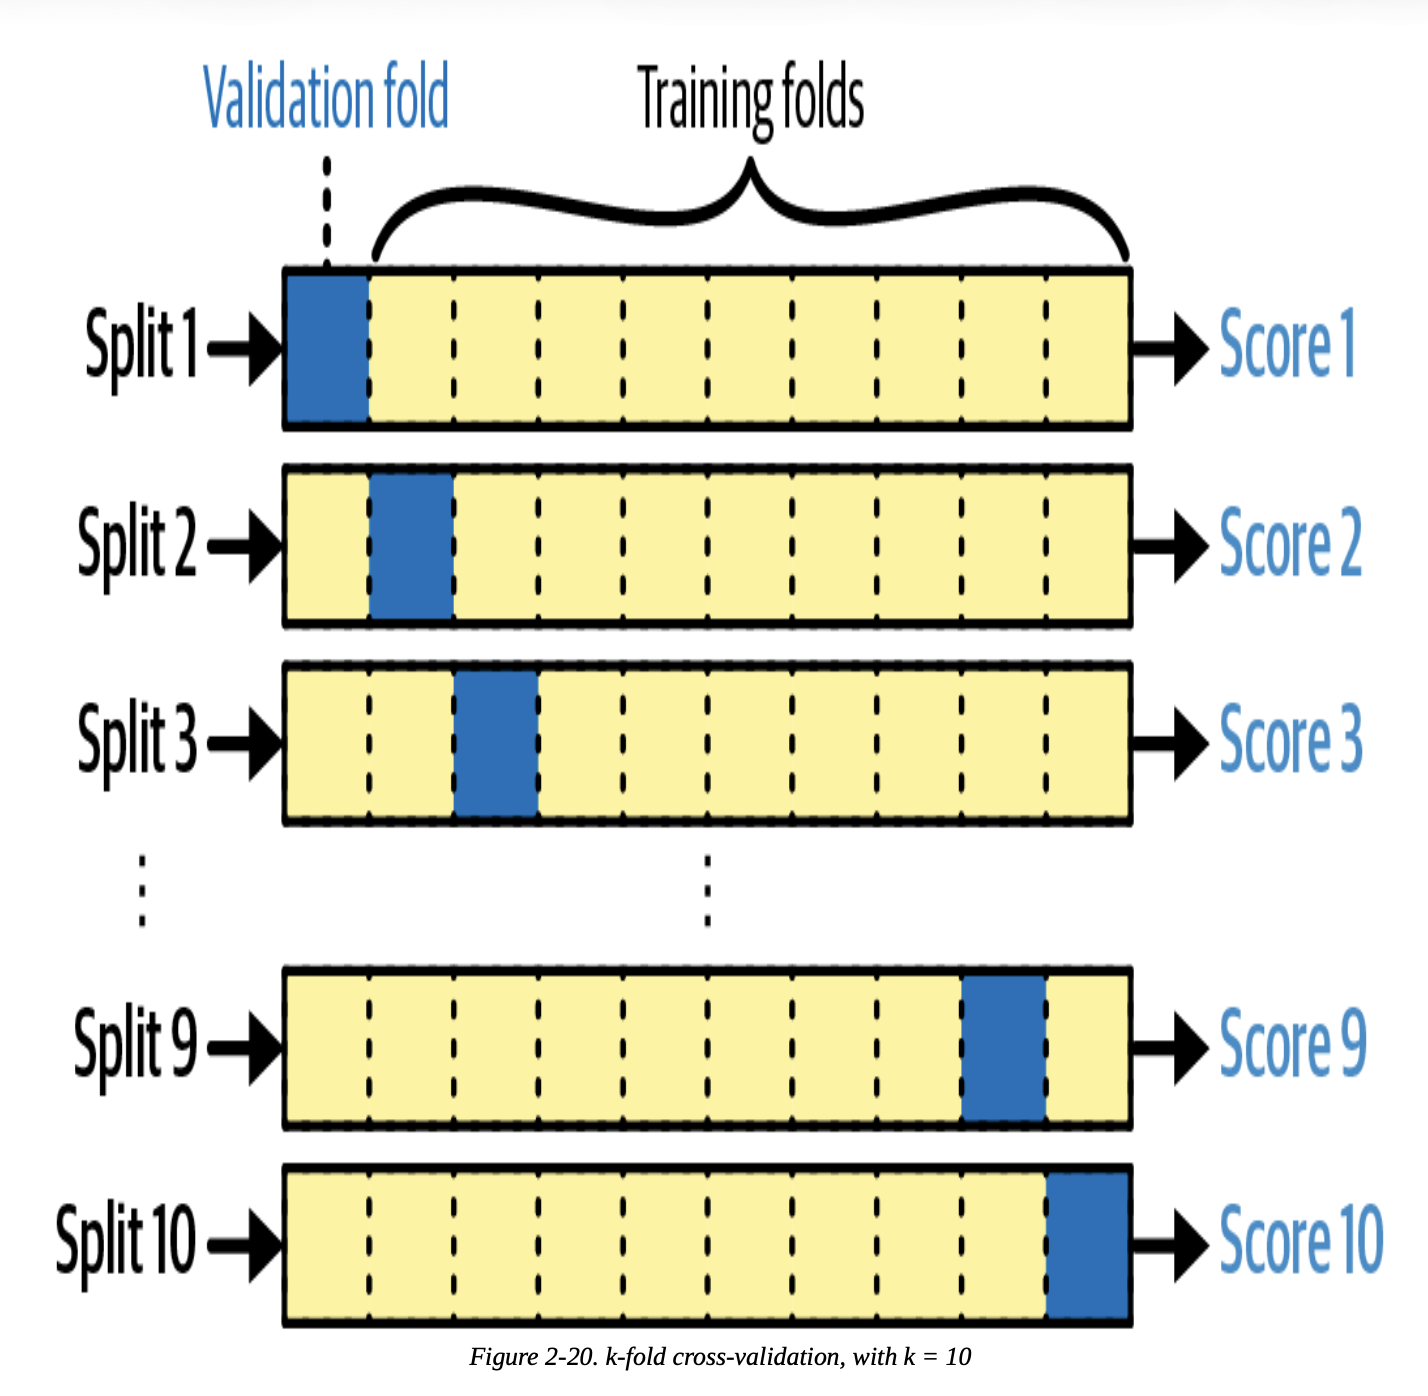

* Note :- Scikit-Learn provides a convenient `cross_val_score()` function that does just that, and it returns an array containing
the k evaluation scores. For example, let’s use it to evaluate our tree regressor, using k = 10

#### note : here its -cross_val_score , it means negative , why ?

* Why "neg" (negative)? sklearn's convention: higher score = better for ALL scoring metrics. But RMSE is an error — lower is better. So sklearn flips the sign (negates it) to stay consistent with "higher = better" across all its scoring functions.

`WARNING`

Scikit-Learn’s cross-validation features expect a utility function (greater is better) rather than a cost function (lower
is better), so the scoring function is actually the opposite of the RMSE. It’s a negative value, so you need to switch
the sign of the output to get the RMSE score

In [101]:
from sklearn.model_selection import cross_val_score
tree_rmses = -cross_val_score(tree_reg, housing , housing_labels,
                              scoring = "neg_root_mean_squared_error" , cv = 10)
tree_rmses

array([64607.89604624, 66409.0627187 , 66203.41031283, 65863.76434319,
       68086.79141027, 66534.53308312, 66923.49892937, 68532.21066423,
       66141.53554919, 66208.69621463])

What it does: Instead of training once and getting one RMSE (like you just did),
this runs the entire train+evaluate process 10 times (cv=10 = 10 folds),
each time using a different 1/10th as validation
Output: An array of 10 RMSE scores (one per fold) — not a single number.

In [102]:
# let's look at the results :
pd.Series(tree_rmses).describe()

#it means how much error now its producing right
# this shows the spread of RMSE errors across the 10 folds.

,0
count,10.000000
mean,66551.139927
std,1110.386369
min,64607.896046
25%,66157.004240
50%,66308.879467
75%,66826.257468
max,68532.210664


* As we can see that the `DecisionTreeRegressor` is prouducing same error as linear regression model . So basically cross-validation helps in measuring how precide this estimate is(i.e its standard deviation).

* the decision tree has an RMSE of about 66k , with a standard deviation of about 1,103.

* `NOTE` - we wouldn't get this info if we only used one validation set.

If you compute the same metric for the linear regression model, you will find that the mean RMSE is 70,003 and the
standard deviation is 4,182. So the decision tree model seems to perform very slightly better than the linear model, but
the difference is minimal due to severe overfitting. We know there’s an overfitting problem because the training error is
low (actually zero) while the validation error is high.

### Using RandomForestRegressor

* Random forests work by training many decisions trees on random subsets of the features , then averaging out their predictions. Such models are composed of many other models are called `ensemble`

* `Note` if the underlying models are very diverse , then their errors will not be very correlated , and therefore avergaing out the predictions will smooth out errors , reduce overfitting , and improve the overall performance .


In [103]:
# Let's code it out
from sklearn.ensemble import RandomForestRegressor
forest_reg = make_pipeline(
    preprocessing, RandomForestRegressor(random_state = 42)
)

forest_rmses = -cross_val_score(forest_reg , housing , housing_labels,
                                scoring = "neg_root_mean_squared_error" , cv = 10)
forest_reg

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(remainder=Pipeline(steps=[('simpleimputer',
                                                              SimpleImputer(strategy='median')),
                                                             ('standardscaler',
                                                              StandardScaler())]),
                                   transformers=[('bedrooms',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('functiontransformer',
                                                                   FunctionTransformer(feature_names_out=<function ratio_name at 0x793...
                                                  ClusterSimilarity(gamma=1,
                                                                    random_state=42),
                                                  ['latitude', 'longitude']),
                                                 ('cat',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehotencoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x793966daa0d0>)])),
                ('randomforestregressor',
                 RandomForestRegressor(random_state=42))])

In [104]:
# let's look at the scores
pd.Series(forest_rmses).describe()


,0
count,10.000000
mean,47052.156858
std,1014.215773
min,45495.976649
25%,46569.493712
50%,47117.033226
75%,47480.519175
max,49155.369239


* So our error went down by a lot(17k rougly), but it means there is still overfitting happenimg ,keep it in mind

## Fine-Tune the  Model

* Evry model has hyperparameters (like n_clusters = 10 in ClusterSimilarity , or max_features in RandomForest) that you set manually - but which value give us the best performance , and testing manually by changing values of hyperparameter is very time consuming so ,

* the fix is `Grid search`




For using scikit class GridSearchCV

1. all we need to do is tell it which hyperparameters u want it to experiment with and what values to try out

2. and it will use cross-validation to eva;uate all the possible combinations of hyperparameter values

`IN-SHORT`

* whole concept of grid search is that instead of setting up manually and run tests one by one ,  we will provide it some values to run at once and then give us the best possible search ,

In [ ]:
# Let's test it out
from sklearn.model_selection import GridSearchCV
from sklearn.compose import make_column_selector , make_column_transformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor

# creating new pipeline
full_pipeline = Pipeline([  # also providing names
    ("preprocessing" , preprocessing),
    ("random_forest" , RandomForestRegressor(random_state = 42))
])

# this step it providing the values to test it on
param_grid = [
    {'preprocessing__geo__n_clusters' : [5,8,10],
     'random_forest__max_features' : [4,6,8]},
    {'preprocessing__geo__n_clusters' : [10,15],
     'random_forest__max_features'  : [6,8,10]}
]

# code for passing the pipeline and pararm_grid(to test the values) for performing gridsearch
grid_search = GridSearchCV(full_pipeline , param_grid, cv= 2,
                           scoring = "neg_root_mean_squared_error")

# let's provide it the data to learn from
grid_search.fit(housing, housing_labels)


Syntax: stepname__substepname__hyperparameter

* preprocessing → step name (in full_pipeline)

* geo → sub-step name (inside preprocessing, your ClusterSimilarity step)

* n_clusters → the actual hyperparameter being tuned

Double underscore (__) separates each level of nesting.

In [ ]:
grid_search.best_params_
# so from given values , n_cluster :15 , max_features : 6

In [ ]:
cv_res = pd.DataFrame(grid_search.cv_results_)
# print(cv_res)
cv_res.sort_values(by = "mean_test_score" , ascending = False , inplace = True)
cv_res.head(15) # note : the 1st column is the row 1D
# that first column (12, 13, 6, 9, 7) is just the row index from the original



* The mean test RMSE score for the best model is 43,612 which is better than the score we got earlier using the default
hyperparameter values (which was 47052.).

## Randomized Search

* GridSearchCV is fine but we can only exploring relatively few combinations , but `RandomizedSearchCV` is often preferable , especially when the hyperparameter search space is large .

* `Working` - it evaluates a fixed number of combinations , selecting a random value for each hyperparameter at every iteration

* `ADV` -

1. Better coverage on continuous/many-valued hyperparameters

* Random search tests many different values (e.g. 1000 iterations) per hyperparameter
* Grid search only tests the exact few values you manually listed

2. Doesn't waste time on useless hyperparameters

* If a hyperparameter barely matters but has 10 possible values:
* Grid search → training time × 10 (forced to try all combos)
Random search → no extra cost, unaffected

3. Scales better with many hyperparameters

* 6 hyperparameters × 10 values each → grid search = 1,000,000 combinations (forced)
* Random search → you control iteration count directly, regardless of hyperparameter count

Grid search = exhaustive but explodes in size/time. Random search = flexible, efficient, you control the budget (iterations) yourself.

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

param_distribs = {'preprocessing__geo__n_clusters' : randint(low = 3 , high = 50),
                  'random_forest__max_features' : randint(low = 2 , high = 20)}

rnd_search = RandomizedSearchCV(
    full_pipeline, param_distributions = param_distribs , n_iter = 10, cv =3,
    scoring = "neg_root_mean_squared_error" , random_state = 42
)

In [ ]:
rnd_search.fit(housing, housing_labels)

In [ ]:
rnd_search.best_params_ # lets see what is the best_params_ to train our model on

In [ ]:
cv_results = pd.DataFrame(rnd_search.cv_results_)
cv_results.sort_values(by = "mean_test_score" , ascending = False, inplace = True)
cv_results.head(16)


HalvingRandomSearchCV / HalvingGridSearchCV
* Goal: Save time/resources while still searching hyperparameters
* How: Start with MANY candidates, but train each on limited resources (small data subset or few iterations)
* Only the best-performing candidates move to next round
* Next round → more resources, fewer candidates
* Repeat until final round uses full resources on the best few
* Result: Faster overall, since weak candidates get eliminated early (before wasting full training time on them)

One-liner: Elimination-style tournament — start with many candidates cheaply, keep only the winners, give them more resources each round.

## Ensemble Methods

1. Combine multiple different models together → often performs better than any single best model

2. Works best when models make different types of errors (diversity helps)
* Example: Train KNN + Random Forest separately → final prediction = average of both

3. Same idea as Random Forest itself (combining many decision trees)

## Analyzing the best models and their erros

* best_estimator_ = the actual fitted, trained pipeline using the best hyperparameters found (n_clusters=45, max_features=9).

* This includes BOTH your preprocessing steps AND the trained RandomForest — the whole thing, ready to use.


In [ ]:
final_model = rnd_search.best_estimator_ # includes preprocessing

feature_importances = final_model["random_forest"].feature_importances_
feature_importances.round(2)


* Each number = importance score for one feature (0 to 1 scale, all scores roughly sum to 1).

* Higher number = more important for predictions. Looking at your output,
one value stands out: 0.19 — much higher than most others (which are 0.01-0.07) — meaning that particular feature
(likely median_income, historically the strongest predictor in this dataset)
contributes far more to predictions than most others.

* Values near 0 (like several 0.01s, 0.) → those features barely matter to the model's decisions.


* final_model["random_forest"] → reach INTO the pipeline and grab just the RandomForest step (by its name, same way you referenced preprocessing__geo__n_clusters earlier)

* .feature_importances_ → a built-in RandomForest attribute — after training, it calculates how much each feature contributed to reducing prediction error across all its trees

Let’s sort these importance `scores` in `descending order` and display them next to their corresponding attribute names:

Match these importance values to actual feature names, since right now it's just a plain array with no labels:

In [ ]:
importance_pairs = sorted(zip(feature_importances, final_model["preprocessing"].get_feature_names_out()),
           reverse = True)

# print(importance_pairs)  -> for printing all the features with their 0-1 values and the labels of each

print("TOP 5 most important features:")
for score, name in importance_pairs[:5]:
    print(f"{name}: {score:.4f}")
print()


print("Worst 5 features or BOTTOM 5 least important features: ")
for score, name in importance_pairs[-5:] :
  print(f"{name}: {score:.4f}")
print()

In [ ]:
import joblib
joblib.dump(final_model, "final_model.pkl")
from google.colab import files
files.download("final_model.pkl")

## Evaluating  System on the Test Set


Run final_model on the test set (which you've never touched until now) → get predictions → compare against actual test labels → this gives your true, unbiased performance estimate before deployment.

 Steps :-

*  Split test set into features (X_test) and labels (y_test)
*  Same pattern as before, but this is the UNTOUCHED test set —
* first and only time we use it
*  Predict on test set using the final tuned model
* Calculate final RMSE — this is your TRUE generalization error

In [ ]:
X_test = strat_test_set.drop("median_house_value" , axis = 1)
y_test = strat_test_set["median_house_value"].copy()

final_predictions = final_model.predict(X_test)
print(f"the final predictions of the model : {final_predictions[:3].round(3)} ")

In [ ]:
print(f"the Actual values of the model : {y_test.iloc[:3].values}")

final_rmses = root_mean_squared_error(y_test, final_predictions)
print(f"final rmse on test set : {final_rmses}")

`NOTE`

1. so we see that 41k dollars error is there on test set and one think comes in mind that :

* Point estimate (41,445 RMSE) alone isn't always convincing — what if the new model is only 0.1% better than the current one? Need to know how precise/reliable that number is.


2. `Soltuion`
* Compute a 95% confidence interval using scipy.stats.bootstrap() — gives a range instead of one fixed number.

`Note` `Confidence interval` = "how much could this error number vary?" — not just one number, but a believable range for the true error.

In [ ]:
# let's code it out

from scipy import stats

def rmses(squared_errors):
  return np.sqrt(np.mean(squared_errors))

confidence = 0.95 # checking at 90 percent
squared_errors = (final_predictions - y_test) ** 2

print(f"squared_errors shape : {squared_errors.shape}")
print(f"squared_errors sample / the first 5 squared error values: {squared_errors[:5]}")


In [ ]:
boot_results = stats.bootstrap([squared_errors] , rmses ,
                               confidence_level = confidence,
                               random_state = 42)

print(f"boot_results : {boot_results}")


rmses_lower , rmses_upper = boot_results.confidence_interval
print(f"at 95 percent interval : [{rmses_lower:.2f}, {rmses_upper:.2f}]")


In [ ]:
boot_results